# MLP para classificar a evolução de casos de SRAG (cura × óbito)

**Disciplina:** Deep Learning — Trabalho Prático (Frente 3.1: *Multilayer Perceptrons*)
**Grupo:** Juliano Costa, Victor Hugo Jesus

**Dataset:** Banco de dados da Síndrome Respiratória Aguda Grave (SRAG) — 2019 a 2026 (SIVEP-Gripe / Ministério da Saúde)
- Portal Brasileiro de Dados Abertos: https://dados.gov.br/dados/conjuntos-dados/srag-2021-e-2022
- Arquivos (OpenDataSUS): https://dadosabertos.saude.gov.br/dataset/srag-2019-a-2026

**Protocolo temporal:** treino = 2020–2021 · validação = 2022 · teste = 2023

### Como executar no Google Colab
1. `Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)`.
2. `Ambiente de execução → Executar tudo`. O notebook baixa os arquivos `.parquet` direto do servidor do Ministério da Saúde.
3. Para um teste rápido de ponta a ponta (amostras pequenas e poucas épocas), mude `RAPIDO = True` na seção de configuração.
4. Opcional: `USAR_DRIVE = True` guarda os dados e resultados no Google Drive, evitando baixar tudo de novo a cada sessão.

### Roteiro
0. Configuração
1. Definição do problema
2. Carga, limpeza e seleção de atributos (objetivo aqui é evitar data leakage))
3. Análise exploratória (EDA)
4. Pré-processamento (ajustado apenas no treino, tambem evitar data leakage)
5. Implementação da MLP e do laço de treinamento
6. Experimento 1 — largura × profundidade (capacidade)
7. Experimento 2 — estratégias de regularização
8. Experimento 3 — busca de hiperparâmetros com Optuna
9. Seleção e comparação de ≥ 3 arquiteturas promissoras (retreino completo, várias sementes)
10. Avaliação final no teste (2023) e custo × efetividade
11. Limitações e conclusões finais.

## 0. Configuração

In [1]:
# Instala o Optuna
%pip install -q optuna

In [2]:
import os, gc, time, json, copy, math, random, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import optuna
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE, '| torch', torch.__version__, '| optuna', optuna.__version__)
if DEVICE.type == 'cpu':
    print('ATENÇÃO: sem GPU. Ative a GPU no Colab ou use RAPIDO=True — em CPU o treinamento completo fica lento.')

Dispositivo: cuda | torch 2.11.0+cu130 | optuna 5.0.0


In [3]:
# ===================== CONFIGURAÇÃO GERAL =====================
RAPIDO = os.environ.get('SRAG_RAPIDO', '0') == '1'   # True = teste rápido de ponta a ponta
SEED = 42
USAR_DRIVE = True                                   # True = salva dados/resultados no Google Drive

DATA_DIR = os.environ.get('SRAG_DATA_DIR', '/content/dados_srag')
OUT_DIR = os.environ.get('SRAG_OUT_DIR', '/content/resultados')
if USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/srag_dl/dados'
    OUT_DIR = '/content/drive/MyDrive/srag_dl/resultados'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Arquivos .parquet publicados no OpenDataSUS. Se o Ministério atualizar o arquivo,
# troque DATA_VERSAO pela data que aparece no nome do recurso no portal (ex.: "Banco vivo 23/03/2026").
DATA_VERSAO = '23-03-2026'
URL_BASE = 'https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SRAG/{ano}/INFLUD{aa}-{versao}.parquet'
PARTICOES = {'treino': [2020, 2021], 'validacao': [2022], 'teste': [2023]}

# Definição da população e do alvo
SOMENTE_HOSPITALIZADOS = True        # mantém apenas casos com HOSPITAL = 1 (internados)
INCLUIR_OBITO_OUTRAS_CAUSAS = False  # EVOLUCAO = 3 (óbito por outras causas) é excluído por padrão
INCLUIR_VARS_INTERNACAO = False      # UTI, suporte ventilatório etc. (ver discussão de vazamento)

# Orçamento computacional
AMOSTRA_POR_ANO = None     # None = usa todos os registros de cada ano
HPO_TRAIN_N = 300_000      # amostra do treino usada nos experimentos 1 e 3 (Optuna)
HPO_VAL_N = 200_000        # amostra da validação usada nos experimentos 1, 2 e 3
REG_TRAIN_N = 20_000       # treino pequeno no experimento 2 para tornar o overfitting observável
FINAL_TRAIN_N = None       # None = treino completo (2020–2021) no retreino das finalistas
N_TRIALS = 40
MAX_EPOCAS_GRID = 20
MAX_EPOCAS_REG = 80
MAX_EPOCAS_HPO = 30
MAX_EPOCAS_FINAL = 40
PACIENCIA = 5
N_SEEDS_FINAL = 3

if RAPIDO:
    AMOSTRA_POR_ANO = 40_000
    HPO_TRAIN_N, HPO_VAL_N, REG_TRAIN_N, FINAL_TRAIN_N = 30_000, 20_000, 5_000, 60_000
    N_TRIALS, MAX_EPOCAS_GRID, MAX_EPOCAS_REG, MAX_EPOCAS_HPO, MAX_EPOCAS_FINAL = 6, 3, 6, 4, 5
    PACIENCIA, N_SEEDS_FINAL = 2, 2

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print('RAPIDO =', RAPIDO, '| dados em', DATA_DIR, '| resultados em', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RAPIDO = False | dados em /content/drive/MyDrive/srag_dl/dados | resultados em /content/drive/MyDrive/srag_dl/resultados


## 1. Definição do problema

**Contexto.** A SRAG é a forma grave das infecções respiratórias (COVID-19, influenza, VSR e outros vírus). Todo caso de SRAG hospitalizado e todo óbito por SRAG no Brasil é notificado no SIVEP-Gripe. A ficha registra dados demográficos, sinais e sintomas, comorbidades, vacinação e, ao final, a **evolução** do caso.

**Utilidade da previsão.** Um modelo que estime, **no momento da notificação/internação**, o risco de óbito pode apoiar a priorização de leitos, o acompanhamento de pacientes de maior risco e o planejamento de vigilância. O objetivo aqui é acadêmico: entender o comportamento de MLPs (capacidade, regularização, hiperparâmetros) e a **generalização temporal** do modelo. Não se trata de uma ferramenta clínica validada.

**Unidade de observação.** Uma notificação de caso de SRAG hospitalizado (uma linha do SIVEP-Gripe). A base é anonimizada e não há identificador de paciente, por isso não é possível agrupar notificações repetidas de uma mesma pessoa (ver limitações).

**Variável alvo.** `EVOLUCAO` (1 = cura, 2 = óbito, 3 = óbito por outras causas, 9 = ignorado). Definimos `y = 1` para **óbito** (código 2) e `y = 0` para **cura** (código 1). Registros sem desfecho (vazio ou 9) não têm rótulo e são descartados. O código 3 é excluído por padrão porque o objetivo é o óbito associado à SRAG (o parâmetro `INCLUIR_OBITO_OUTRAS_CAUSAS` permite incluí-lo como óbito).

**Tipo de problema.** Classificação **binária** com desbalanceamento moderado (óbito é a classe minoritária).

**Divisão temporal.** Treino = casos de 2020–2021, validação = 2022, teste = 2023 (ano epidemiológico do arquivo). A divisão imita o uso real (treinar com o passado e prever o futuro) e avalia a robustez a mudanças no tempo: variantes do SARS-CoV-2, vacinação, protocolos de tratamento e perfil dos pacientes. Os dados não são embaralhados entre anos e nenhuma informação de 2022–2023 é usada para ajustar transformações ou pesos.

## 2. Carga, limpeza e seleção de atributos

### 2.1 Seleção de variáveis e risco de vazamento
A pergunta é: *"com o que se sabe na notificação/internação, qual o risco de óbito?"*. Por isso usamos apenas informações disponíveis nesse momento e excluímos variáveis que só existem depois do desfecho ou que são consequência do agravamento:

| Grupo | Variáveis | Decisão |
|---|---|---|
| Demografia | idade (`NU_IDADE_N`+`TP_IDADE`), `CS_SEXO`, `CS_GESTANT`, `CS_RACA`, `CS_ESCOL_N`, `CS_ZONA`, `SG_UF_NOT` | **usar** |
| Sinais e sintomas | febre, tosse, garganta, dispneia, desconforto respiratório, saturação O₂ < 95%, diarreia, vômito, dor abdominal, fadiga, perda de olfato/paladar, outros | **usar** |
| Comorbidades / fatores de risco | cardiopatia, diabetes, obesidade, doença renal, neurológica, pneumopatia, imunodepressão, etc. | **usar** |
| Contexto e vacinação | `NOSOCOMIAL`, `AVE_SUINO`, `VACINA` (gripe), `VACINA_COV` | **usar** |
| Tempos derivados | dias entre 1º sintoma e notificação; dias entre 1º sintoma e internação | **usar** (conhecidos na internação) |
| Evolução hospitalar | `UTI`, `SUPORT_VEN`, `RAIOX_RES`, `ANTIVIRAL`, datas de UTI | **excluir** por padrão: ocorrem durante a internação e funcionam como *proxy* do agravamento (podem ser ativadas com `INCLUIR_VARS_INTERNACAO`) |
| Encerramento | `DT_EVOLUCAO`, `DT_ENCERRA`, `CLASSI_FIN`, `CRITERIO`, resultados laboratoriais | **excluir**: definidos no fechamento do caso (vazamento direto ou quase direto do alvo) |
| Datas absolutas / identificação | `DT_NOTIFIC`, `SEM_PRI`, códigos de município/unidade | **excluir** como entrada: datas absolutas não extrapolam para anos futuros e códigos de alta cardinalidade favorecem memorização. Usadas só para EDA e para detectar duplicatas |

Os campos categóricos usam 1 = sim, 2 = não, 9 = ignorado. O código **9 e o valor ausente são tratados como categorias próprias**, porque a falta de preenchimento é informativa (casos graves ou fichas preenchidas às pressas).

In [4]:
ALVO_BRUTO = 'EVOLUCAO'
COLS_DATAS = ['DT_NOTIFIC', 'DT_SIN_PRI', 'DT_INTERNA']
COLS_IDADE = ['NU_IDADE_N', 'TP_IDADE']
CAT_DEMO = ['CS_SEXO', 'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N', 'CS_ZONA', 'SG_UF_NOT']
CAT_SINTOMAS = ['FEBRE', 'TOSSE', 'GARGANTA', 'DISPNEIA', 'DESC_RESP', 'SATURACAO', 'DIARREIA',
                'VOMITO', 'DOR_ABD', 'FADIGA', 'PERD_OLFT', 'PERD_PALA', 'OUTRO_SIN']
CAT_COMORB = ['FATOR_RISC', 'PUERPERA', 'CARDIOPATI', 'HEMATOLOGI', 'SIND_DOWN', 'HEPATICA', 'ASMA',
              'DIABETES', 'NEUROLOGIC', 'PNEUMOPATI', 'IMUNODEPRE', 'RENAL', 'OBESIDADE', 'OUT_MORBI']
CAT_OUTROS = ['NOSOCOMIAL', 'AVE_SUINO', 'VACINA', 'VACINA_COV']
CAT_INTERNACAO = ['UTI', 'SUPORT_VEN', 'RAIOX_RES', 'ANTIVIRAL']
COLS_AUX = ['HOSPITAL', 'CO_MUN_NOT']   # filtro de população e detecção de duplicatas

CAT_SIM_NAO = CAT_SINTOMAS + CAT_COMORB + CAT_OUTROS + CAT_INTERNACAO
CAT_FEATURES = CAT_DEMO + CAT_SINTOMAS + CAT_COMORB + CAT_OUTROS + (CAT_INTERNACAO if INCLUIR_VARS_INTERNACAO else [])
NUM_FEATURES = ['IDADE', 'ATRASO_NOTIF', 'ATRASO_INTERN']
COLS_CARREGAR = [ALVO_BRUTO] + COLS_AUX + COLS_DATAS + COLS_IDADE + CAT_DEMO + CAT_SIM_NAO
print(f'{len(CAT_FEATURES)} variáveis categóricas + {len(NUM_FEATURES)} numéricas como entrada da rede')

37 variáveis categóricas + 3 numéricas como entrada da rede


In [5]:
def baixar(ano):
    """Baixa o parquet do ano (se ainda não existir localmente)."""
    aa = str(ano)[2:]
    destino = os.path.join(DATA_DIR, f'INFLUD{aa}.parquet')
    if os.path.exists(destino) and os.path.getsize(destino) > 0:
        return destino
    url = URL_BASE.format(ano=ano, aa=aa, versao=DATA_VERSAO)
    print(f'Baixando {url} ...')
    t0 = time.time()
    urllib.request.urlretrieve(url, destino + '.tmp')
    os.replace(destino + '.tmp', destino)
    print(f'  ok: {os.path.getsize(destino)/1e6:.0f} MB em {time.time()-t0:.0f}s')
    return destino


def normalizar_codigo(s):
    """Padroniza códigos (ex.: 1, 1.0, ' 1 ' -> '1'; vazio -> NA) trabalhando só nos valores únicos."""
    codes, uniq = pd.factorize(s, use_na_sentinel=True)
    u = pd.Series(np.asarray(uniq, dtype=object)).astype(str).str.strip().str.upper()
    u = u.str.replace(r'\.0$', '', regex=True)
    u = u.where(~u.isin(['', 'NAN', 'NONE', '<NA>', 'NAT', 'NULL']), None)
    vals = np.append(u.to_numpy(dtype=object), None)
    return pd.Series(vals[codes], index=s.index, dtype='category')


def para_data(s):
    """Converte datas em dd/mm/aaaa ou ISO (aaaa-mm-dd) para datetime."""
    codes, uniq = pd.factorize(s, use_na_sentinel=True)
    u = pd.Series(np.asarray(uniq, dtype=object)).astype(str).str.strip()
    d = pd.to_datetime(u, format='%d/%m/%Y', errors='coerce')
    resto = d.isna()
    if resto.any():
        try:
            d[resto] = pd.to_datetime(u[resto], format='ISO8601', errors='coerce')
        except (ValueError, TypeError):
            d[resto] = pd.to_datetime(u[resto], errors='coerce')
    vals = np.append(d.to_numpy(dtype='datetime64[ns]'), np.datetime64('NaT', 'ns'))
    return pd.Series(vals[codes], index=s.index)


def carregar_ano(ano):
    caminho = baixar(ano)
    nomes = pq.read_schema(caminho).names
    mapa = {n.upper(): n for n in nomes}
    presentes = [c for c in COLS_CARREGAR if c in mapa]
    ausentes = [c for c in COLS_CARREGAR if c not in mapa]
    tab = pq.read_table(caminho, columns=[mapa[c] for c in presentes])
    df = tab.to_pandas(strings_to_categorical=True)
    del tab
    df.columns = [c.upper() for c in df.columns]
    for c in ausentes:
        df[c] = pd.Series(np.nan, index=df.index, dtype='category')
    info = {'registros_brutos': len(df), 'colunas_ausentes': ', '.join(ausentes) or '-'}

    # --- alvo e população ---
    df[ALVO_BRUTO] = normalizar_codigo(df[ALVO_BRUTO])
    evol = df[ALVO_BRUTO].astype(object).fillna('vazio').value_counts()
    for k, v in evol.items():
        info[f'EVOLUCAO={k}'] = int(v)
    validos = ['1', '2'] + (['3'] if INCLUIR_OBITO_OUTRAS_CAUSAS else [])
    df = df[df[ALVO_BRUTO].isin(validos)].copy()
    info['com_desfecho_valido'] = len(df)
    df['HOSPITAL'] = normalizar_codigo(df['HOSPITAL'])
    if SOMENTE_HOSPITALIZADOS:
        df = df[df['HOSPITAL'] == '1'].copy()
    info['hospitalizados'] = len(df)

    # --- padronização dos campos ---
    for c in CAT_DEMO + CAT_SIM_NAO + ['TP_IDADE', 'CO_MUN_NOT']:
        df[c] = normalizar_codigo(df[c])
    for c in CAT_SIM_NAO:   # alguns anos usam S/N em vez de 1/2
        df[c] = df[c].astype(object).replace({'S': '1', 'N': '2'}).astype('category')
    df['CS_SEXO'] = df['CS_SEXO'].astype(object).replace({'1': 'M', '2': 'F', '9': 'I'}).astype('category')
    for c in COLS_DATAS:
        df[c] = para_data(df[c])

    # --- duplicatas exatas (mesmos dados em todas as colunas carregadas) ---
    dup = df.duplicated()
    info['duplicatas_removidas'] = int(dup.sum())
    df = df[~dup].copy()

    if AMOSTRA_POR_ANO is not None and len(df) > AMOSTRA_POR_ANO:
        df = df.sample(AMOSTRA_POR_ANO, random_state=SEED)
    df['ANO'] = ano
    info['final'] = len(df)
    return df, info


dfs, INFO_CARGA = [], {}
for ano in sorted(sum(PARTICOES.values(), [])):
    t0 = time.time()
    d, info = carregar_ano(ano)
    dfs.append(d); INFO_CARGA[ano] = info
    print(f'{ano}: {info["registros_brutos"]:>9,} brutos -> {info["final"]:>9,} usados  ({time.time()-t0:.0f}s)')
    gc.collect()

df = pd.concat(dfs, ignore_index=True)
del dfs; gc.collect()
for c in CAT_DEMO + CAT_SIM_NAO + ['TP_IDADE', 'CO_MUN_NOT', ALVO_BRUTO, 'HOSPITAL']:
    df[c] = df[c].astype('category')
print(f'\nTotal: {len(df):,} registros | memória: {df.memory_usage(deep=True).sum()/1e9:.2f} GB')
display(pd.DataFrame(INFO_CARGA).T.fillna(0))

2020: 1,206,920 brutos -> 1,031,783 usados  (22s)
2021: 1,745,672 brutos -> 1,480,337 usados  (30s)
2022:   560,577 brutos ->   470,059 usados  (9s)
2023:   279,453 brutos ->   241,411 usados  (5s)

Total: 3,223,590 registros | memória: 0.66 GB


,registros_brutos,colunas_ausentes,EVOLUCAO=1,EVOLUCAO=2,EVOLUCAO=vazio,EVOLUCAO=9,EVOLUCAO=3,com_desfecho_valido,hospitalizados,duplicatas_removidas,final
2020,1206920,-,773231,315445,76522,24272,17450,1088676,1031880,97,1031783
2021,1745672,-,1093167,443524,142650,42788,23543,1536691,1480432,95,1480337
2022,560577,-,395099,92635,44606,13546,14691,487734,470150,91,470059
2023,279453,-,226151,24944,13980,6077,8301,251095,241464,53,241411


### 2.2 Variáveis derivadas, alvo e valores anômalos
- **IDADE** em anos, convertida a partir de `NU_IDADE_N` e `TP_IDADE` (1 = dias, 2 = meses, 3 = anos).
- **ATRASO_NOTIF** = dias entre o 1º sintoma e a notificação; **ATRASO_INTERN** = dias entre o 1º sintoma e a internação.
- Valores impossíveis ou muito improváveis (idade < 0 ou > 110 anos; atrasos negativos ou > 90 dias) são tratados como **erro de digitação** e convertidos em ausentes. Depois são imputados (com indicador de ausência), em vez de descartar a linha inteira.

In [6]:
# --- 1) Limpeza das datas: datas impossíveis (ex.: ano 0202 ou 2920, erro de digitação) viram ausentes ---
DATA_MIN, DATA_MAX = pd.Timestamp('2019-01-01'), pd.Timestamp('2026-12-31')
datas_invalidas = {}
for c in COLS_DATAS:
    s = df[c]
    if not pd.api.types.is_datetime64_any_dtype(s):
        s = pd.to_datetime(s, errors='coerce')
    preenchida = s.notna()
    ok = preenchida & (s >= DATA_MIN) & (s <= DATA_MAX)
    datas_invalidas[c] = (preenchida & ~ok).groupby(df['ANO']).sum()
    df[c] = s.where(ok).astype('datetime64[ns]')
display(Markdown('**Datas fora de 2019–2026 convertidas em ausentes (por ano):**'))
display(pd.DataFrame(datas_invalidas))

# --- 2) Variáveis derivadas ---
idade = pd.to_numeric(df['NU_IDADE_N'].astype(str), errors='coerce')
tp = df['TP_IDADE'].astype(object)
df['IDADE'] = np.where(tp == '1', idade / 365.25, np.where(tp == '2', idade / 12, idade))
df['ATRASO_NOTIF'] = (df['DT_NOTIFIC'] - df['DT_SIN_PRI']).dt.days
df['ATRASO_INTERN'] = (df['DT_INTERNA'] - df['DT_SIN_PRI']).dt.days

# --- 3) Valores anômalos -> ausentes ---
regras = {'IDADE': (0, 110), 'ATRASO_NOTIF': (0, 90), 'ATRASO_INTERN': (0, 90)}
anom = {}
for c, (lo, hi) in regras.items():
    fora = (df[c] < lo) | (df[c] > hi)
    anom[c] = fora.groupby(df['ANO']).sum()
    df.loc[fora, c] = np.nan
display(Markdown('**Valores anômalos convertidos em ausentes (por ano):**'))
display(pd.DataFrame(anom))

# --- 4) Alvo, partição e mês ---
df['y'] = df[ALVO_BRUTO].astype(object).isin(['2', '3']).astype(np.int8)
df['PARTICAO'] = df['ANO'].map({a: p for p, anos in PARTICOES.items() for a in anos})
df['MES_SIN_PRI'] = df['DT_SIN_PRI'].dt.to_period('M')
df = df.drop(columns=['NU_IDADE_N'])
print(df['PARTICAO'].value_counts())

**Datas fora de 2019–2026 convertidas em ausentes (por ano):**

,DT_NOTIFIC,DT_SIN_PRI,DT_INTERNA
ANO,,,
2020,0,0,10
2021,0,0,11
2022,0,0,7
2023,0,0,3


**Valores anômalos convertidos em ausentes (por ano):**

,IDADE,ATRASO_NOTIF,ATRASO_INTERN
ANO,,,
2020,38,12611,4583
2021,50,16687,7116
2022,26,4522,5196
2023,10,1778,2457


PARTICAO
treino       2512120
validacao     470059
teste         241411
Name: count, dtype: int64


## 3. Análise exploratória (EDA)
### 3.1 Distribuição do alvo e balanceamento por partição

**`EVOLUCAO` nos arquivos brutos (antes dos filtros):**

,1 cura,2 óbito,vazio,9 ignorado,3 óbito outras causas
2020,773231,315445,76522,24272,17450
2021,1093167,443524,142650,42788,23543
2022,395099,92635,44606,13546,14691
2023,226151,24944,13980,6077,8301


**Base modelada (cura × óbito):**

n  obitos  taxa_obito
PARTICAO  ANO                              
teste     2023   241411   22962        9.51
treino    2020  1031783  290862       28.19
          2021  1480337  417410       28.20
validacao 2022   470059   85640       18.22

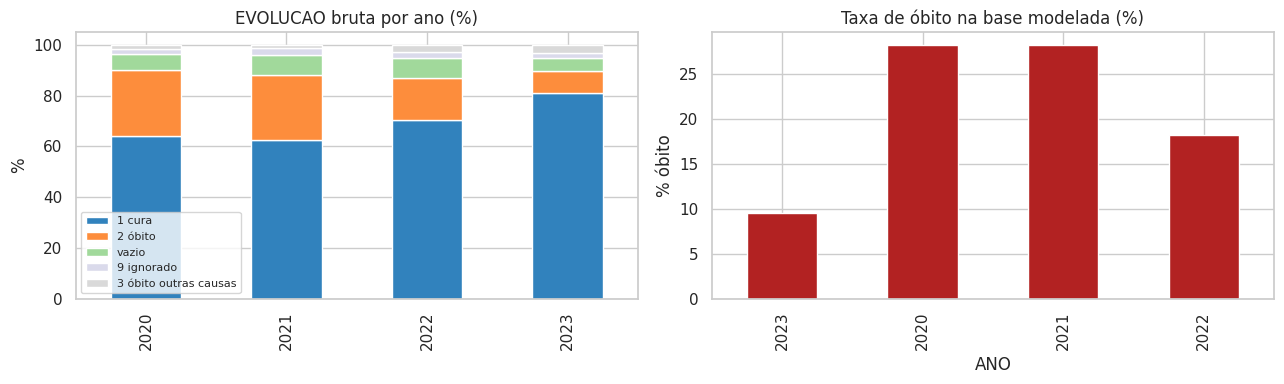

In [7]:
evol_cols = [c for c in pd.DataFrame(INFO_CARGA).T.columns if c.startswith('EVOLUCAO=')]
evol = pd.DataFrame(INFO_CARGA).T[evol_cols].fillna(0).astype(int)
evol.columns = [c.replace('EVOLUCAO=', '') for c in evol.columns]
rotulos = {'1': '1 cura', '2': '2 óbito', '3': '3 óbito outras causas', '9': '9 ignorado', 'vazio': 'vazio'}
evol = evol.rename(columns=rotulos)
display(Markdown('**`EVOLUCAO` nos arquivos brutos (antes dos filtros):**'))
display(evol)

bal = df.groupby(['PARTICAO', 'ANO'])['y'].agg(n='size', obitos='sum', taxa_obito='mean')
bal['taxa_obito'] = (100 * bal['taxa_obito']).round(2)
display(Markdown('**Base modelada (cura × óbito):**'))
display(bal)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(evol.div(evol.sum(1), axis=0) * 100).plot(kind='bar', stacked=True, ax=ax[0], colormap='tab20c')
ax[0].set_title('EVOLUCAO bruta por ano (%)'); ax[0].set_ylabel('%'); ax[0].legend(fontsize=8)
bal.reset_index().plot(x='ANO', y='taxa_obito', kind='bar', ax=ax[1], color='firebrick', legend=False)
ax[1].set_title('Taxa de óbito na base modelada (%)'); ax[1].set_ylabel('% óbito')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_alvo.png', dpi=120); plt.show()

**O que observar:** a proporção de óbitos muda bastante entre os anos (alta em 2020–2021, no pico da COVID-19, e menor em 2022–2023, após a vacinação e a Ômicron). Isso é um **deslocamento de prevalência** (*prior shift*): um limiar escolhido em um ano pode não ser ótimo em outro. Por isso (i) usamos métricas pouco sensíveis à prevalência (PR-AUC e ROC-AUC) na seleção, (ii) escolhemos o limiar de decisão na validação (2022, mais próxima do teste) e (iii) analisamos a calibração no teste.

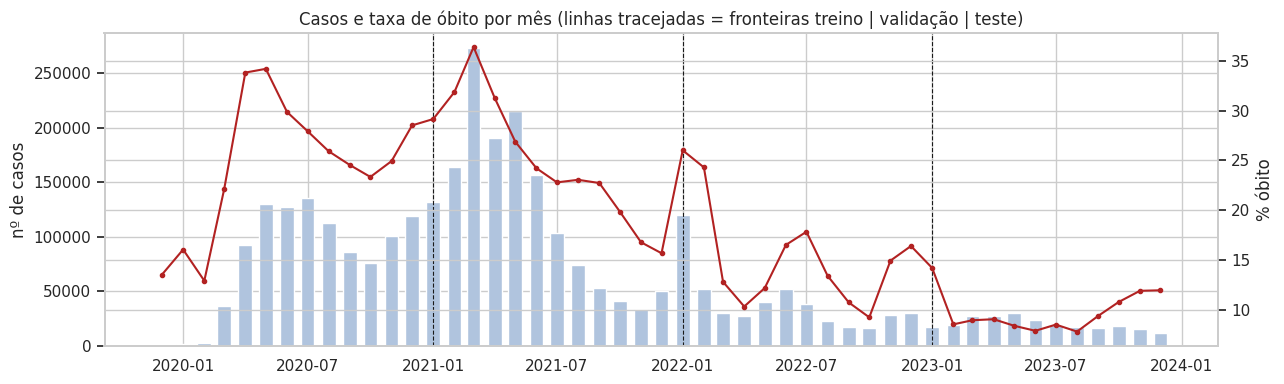

In [8]:
# Série mensal: volume de casos e taxa de óbito por mês do 1º sintoma
mensal = df.dropna(subset=['MES_SIN_PRI']).groupby('MES_SIN_PRI')['y'].agg(['size', 'mean'])
mensal = mensal[mensal['size'] >= 50]
fig, ax1 = plt.subplots(figsize=(13, 4))
x = mensal.index.to_timestamp()
ax1.bar(x, mensal['size'], width=20, color='lightsteelblue', label='casos')
ax1.set_ylabel('nº de casos')
ax2 = ax1.twinx(); ax2.plot(x, 100 * mensal['mean'], color='firebrick', marker='o', ms=3, label='% óbito')
ax2.set_ylabel('% óbito')
for a in [2021, 2022, 2023]:
    ax1.axvline(pd.Timestamp(f'{a}-01-01'), color='k', ls='--', lw=0.8)
ax1.set_title('Casos e taxa de óbito por mês (linhas tracejadas = fronteiras treino | validação | teste)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_serie_mensal.png', dpi=120); plt.show()

### 3.2 Estatísticas descritivas, valores ausentes e duplicatas

**Variáveis numéricas por partição:**

PARTICAO                 teste      treino  validacao
IDADE         count  241401.00  2512032.00  470033.00
              mean       29.84       54.90      47.22
              std        33.92       22.60      33.62
              min         0.00        0.00       0.00
              25%         1.00       42.00       5.00
              50%         7.00       58.00      58.00
              75%        66.00       71.00      77.00
              max       110.00      110.00     110.00
ATRASO_NOTIF  count  239633.00  2482822.00  465537.00
              mean        5.82        8.95       6.40
              std         7.72        9.41       8.62
              min         0.00        0.00       0.00
              25%         2.00        4.00       2.00
              50%         4.00        7.00       4.00
              75%         7.00       11.00       7.00
              max        90.00       90.00      90.00
ATRASO_INTERN count  236427.00  2462838.00  458482.00
              mean        3.56        6.67       3.94
              std         4.71        5.96       4.87
              min         0.00        0.00       0.00
              25%         1.00        3.00       1.00
              50%         3.00        6.00       3.00
              75%         5.00        9.00       5.00
              max        90.00       90.00      90.00

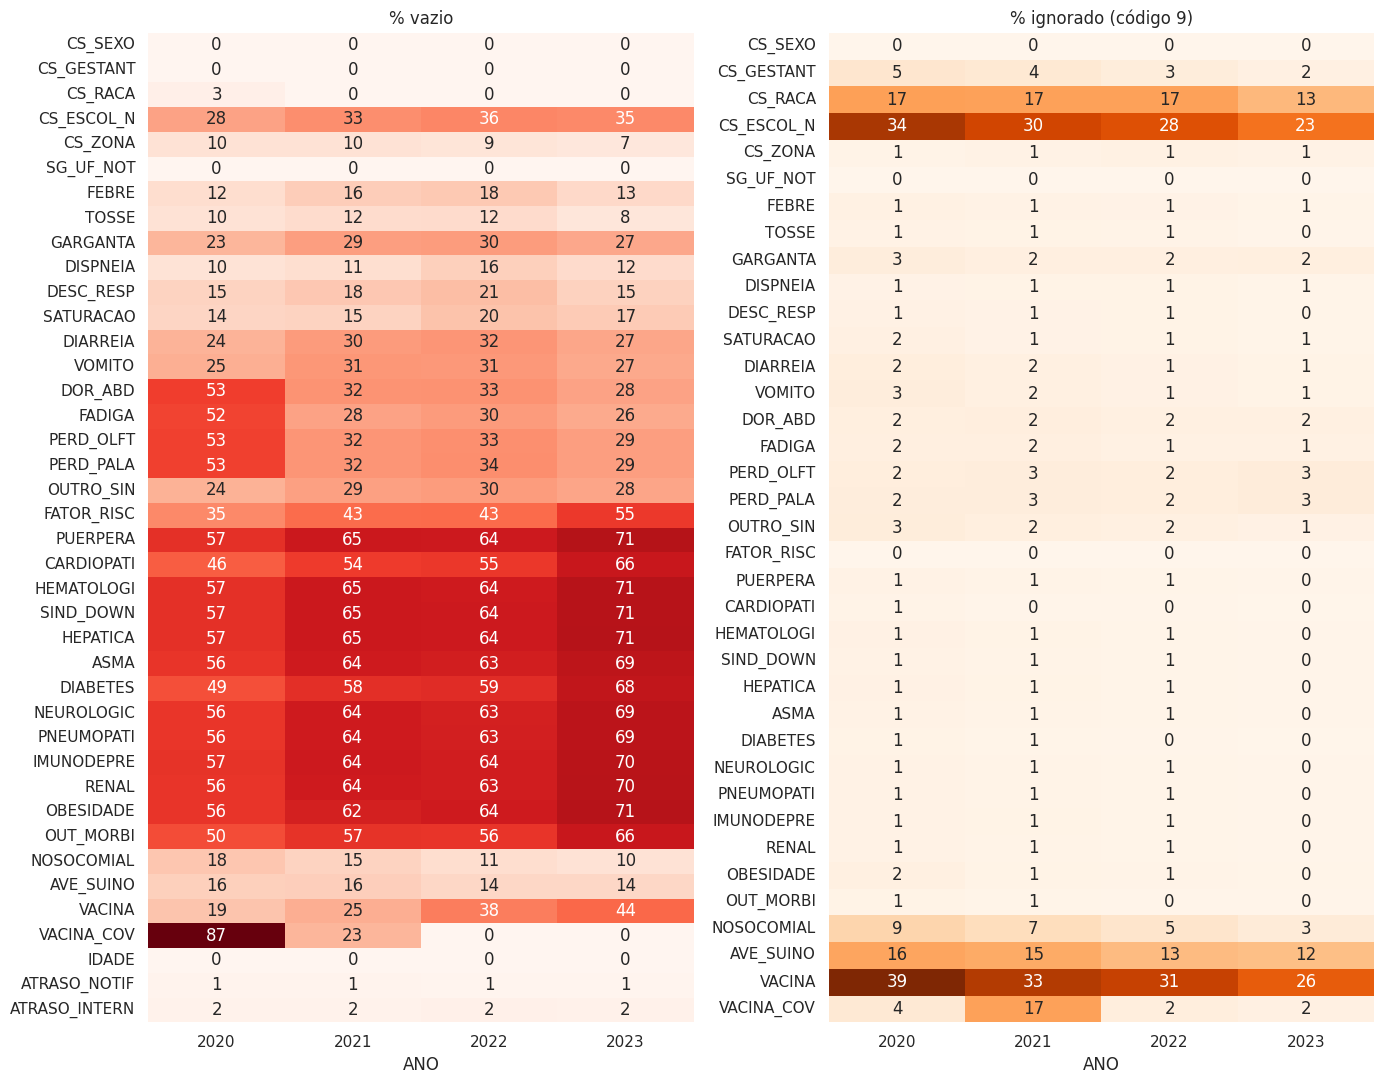

Duplicatas exatas removidas por ano: {2020: 97, 2021: 95, 2022: 91, 2023: 53}


In [9]:
display(Markdown('**Variáveis numéricas por partição:**'))
display(df.groupby('PARTICAO')[NUM_FEATURES].describe().T.round(2))

# % ausente (vazio) e % ignorado (código 9) por variável e ano
aus = df.groupby('ANO')[CAT_FEATURES + NUM_FEATURES].apply(lambda g: g.isna().mean() * 100).T
ign = df.groupby('ANO')[CAT_FEATURES].apply(lambda g: (g.astype(object) == '9').mean() * 100).T
fig, ax = plt.subplots(1, 2, figsize=(14, 11))
sns.heatmap(aus, annot=True, fmt='.0f', cmap='Reds', cbar=False, ax=ax[0]); ax[0].set_title('% vazio')
sns.heatmap(ign, annot=True, fmt='.0f', cmap='Oranges', cbar=False, ax=ax[1]); ax[1].set_title('% ignorado (código 9)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_ausentes.png', dpi=120); plt.show()
print('Duplicatas exatas removidas por ano:', {a: i['duplicatas_removidas'] for a, i in INFO_CARGA.items()})

**O que observar:** sintomas e comorbidades têm muitos campos vazios (o campo costuma ficar em branco quando a resposta é "não"). `VACINA_COV` não existe em 2020 (a vacina ainda não estava disponível) e por isso fica 100% vazio nesse ano. Essa mudança de esquema ao longo do tempo é uma fonte de *drift* entre treino e teste.

### 3.3 Relação das entradas com o alvo (apenas treino)

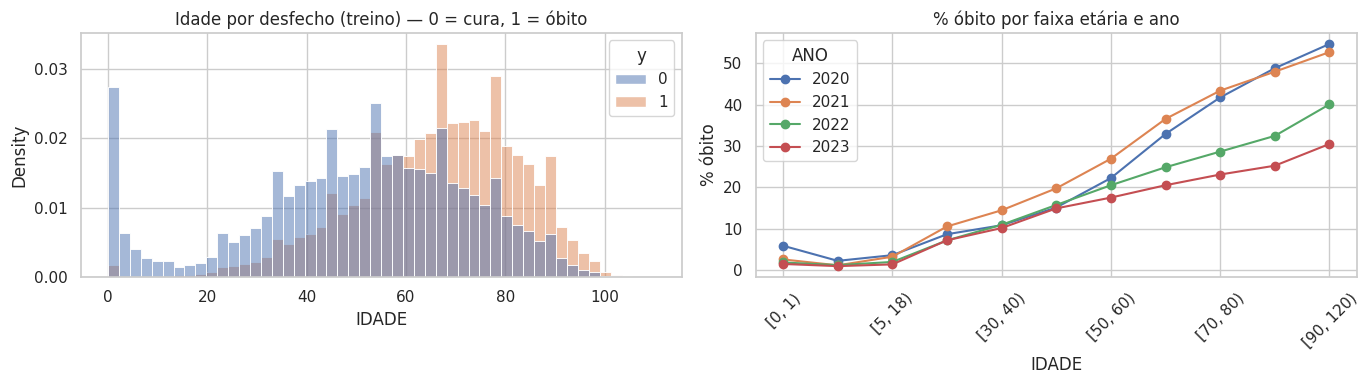

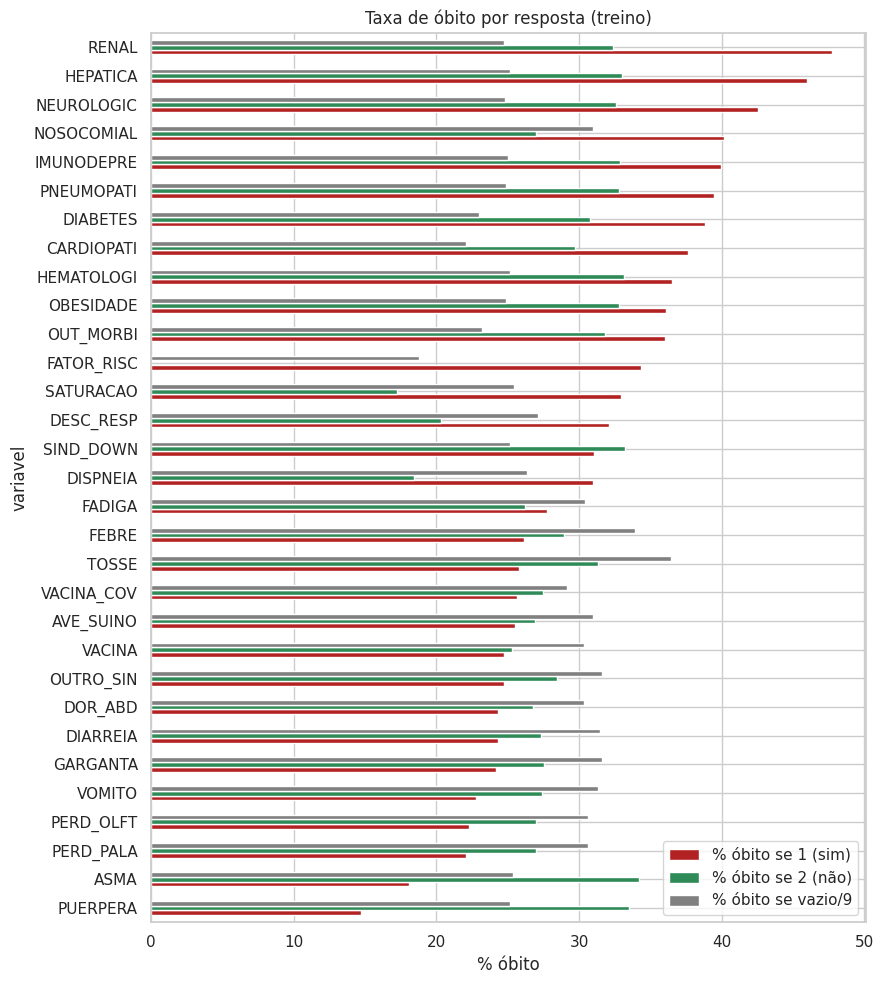

In [10]:
tr = df[df['PARTICAO'] == 'treino']
faixas = pd.cut(df['IDADE'], bins=[0, 1, 5, 18, 30, 40, 50, 60, 70, 80, 90, 120], right=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=tr.sample(min(len(tr), 300_000), random_state=SEED), x='IDADE', hue='y', bins=50,
             stat='density', common_norm=False, ax=ax[0])
ax[0].set_title('Idade por desfecho (treino) — 0 = cura, 1 = óbito')
(df.groupby([faixas, 'ANO'])['y'].mean().unstack() * 100).plot(marker='o', ax=ax[1])
ax[1].set_title('% óbito por faixa etária e ano'); ax[1].set_ylabel('% óbito'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_idade.png', dpi=120); plt.show()

linhas = []
for c in CAT_SINTOMAS + CAT_COMORB + CAT_OUTROS:
    s = tr[c].astype(object)
    linhas.append({'variavel': c,
                   '% óbito se 1 (sim)': 100 * tr.loc[s == '1', 'y'].mean(),
                   '% óbito se 2 (não)': 100 * tr.loc[s == '2', 'y'].mean(),
                   '% óbito se vazio/9': 100 * tr.loc[s.isna() | (s == '9'), 'y'].mean()})
risco = pd.DataFrame(linhas).set_index('variavel').sort_values('% óbito se 1 (sim)')
risco.plot(kind='barh', figsize=(9, 10), color=['firebrick', 'seagreen', 'gray'])
plt.title('Taxa de óbito por resposta (treino)'); plt.xlabel('% óbito')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda_risco_variaveis.png', dpi=120); plt.show()

## 4. Pré-processamento (parâmetros estimados **apenas no treino**)
- **Numéricas:** imputação pela **mediana do treino**, mais um **indicador de ausência** para cada variável. Os atrasos (assimétricos, cauda longa) passam por `log1p`. Em seguida, **padronização** (média 0, desvio 1) com média e desvio do treino.
- **Categóricas:** **one-hot**, com "vazio" (`NA`) e "ignorado" (`9`) como categorias próprias. Categorias que aparecem só na validação ou no teste são ignoradas (`handle_unknown='ignore'`), como aconteceria em produção.
- **Desbalanceamento:** não reamostramos os dados. Tratamos o desbalanceamento com (i) `pos_weight` na BCE (hiperparâmetro `balancear` no Optuna), (ii) métricas adequadas (PR-AUC, Macro-F1, recall do óbito) e (iii) **ajuste do limiar** na validação.
- O `ColumnTransformer` é ajustado com `fit` no treino (2020–2021) e só aplicado com `transform` em 2022 e 2023.

In [11]:
COLS_ATRASO = ['ATRASO_NOTIF', 'ATRASO_INTERN']

def preparar_entrada(d):
    X = d[CAT_FEATURES + NUM_FEATURES].copy()
    for c in CAT_FEATURES:   # mantém dtype category (economiza memória) e cria a categoria 'NA' para vazios
        s = X[c].astype('category')
        if 'NA' not in s.cat.categories:
            s = s.cat.add_categories('NA')
        X[c] = s.fillna('NA')
    return X

preproc = ColumnTransformer([
    ('idade', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), ['IDADE']),
    ('atraso', Pipeline([('imp', SimpleImputer(strategy='median')),
                         ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                         ('sc', StandardScaler())]), COLS_ATRASO),
    ('ausente', MissingIndicator(features='all'), NUM_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32), CAT_FEATURES),
], sparse_threshold=0, verbose_feature_names_out=True)

def transformar(d, chunk=400_000):
    partes = []
    for i in range(0, len(d), chunk):
        partes.append(preproc.transform(preparar_entrada(d.iloc[i:i + chunk])).astype(np.float32))
    return np.vstack(partes)

d_tr = df[df['PARTICAO'] == 'treino'].reset_index(drop=True)
d_va = df[df['PARTICAO'] == 'validacao'].reset_index(drop=True)
d_te = df[df['PARTICAO'] == 'teste'].reset_index(drop=True)

t0 = time.time()
preproc.fit(preparar_entrada(d_tr))          # <- fit SOMENTE no treino
X_tr, X_va, X_te = transformar(d_tr), transformar(d_va), transformar(d_te)
y_tr, y_va, y_te = (d['y'].to_numpy(np.float32) for d in (d_tr, d_va, d_te))
NOMES_FEATURES = list(preproc.get_feature_names_out())
print(f'Pré-processamento em {time.time()-t0:.0f}s | nº de entradas da rede: {X_tr.shape[1]}')
for nome, X, y in [('treino', X_tr, y_tr), ('validação', X_va, y_va), ('teste', X_te, y_te)]:
    print(f'{nome:>10}: X={X.shape}  óbito={y.mean():.3f}')

# Mapeia cada variável original para as colunas que ela gerou (usado na importância por permutação)
GRUPOS = {}
sl = preproc.output_indices_
GRUPOS['IDADE'] = list(range(sl['idade'].start, sl['idade'].stop))
for j, c in enumerate(COLS_ATRASO):
    GRUPOS[c] = [sl['atraso'].start + j]
for j, c in enumerate(NUM_FEATURES):
    GRUPOS[c] = GRUPOS[c] + [sl['ausente'].start + j]
pos = sl['cat'].start
for c, cats in zip(CAT_FEATURES, preproc.named_transformers_['cat'].categories_):
    GRUPOS[c] = list(range(pos, pos + len(cats))); pos += len(cats)
assert pos == sl['cat'].stop

# Libera memória do DataFrame bruto (mantém só o necessário para análises por subgrupo)
meta_te = d_te[['IDADE', 'MES_SIN_PRI']].copy()
del d_tr, d_va
_ = gc.collect()

Pré-processamento em 63s | nº de entradas da rede: 188
    treino: X=(2512120, 188)  óbito=0.282
 validação: X=(470059, 188)  óbito=0.182
     teste: X=(241411, 188)  óbito=0.095


In [12]:
# Tensores no dispositivo (GPU, se disponível). O treino inteiro cabe na memória da T4.
def to_t(a):
    return torch.from_numpy(a).to(DEVICE)

rng = np.random.default_rng(SEED)
def amostra(n_total, n):
    return np.sort(rng.choice(n_total, size=n, replace=False)) if (n is not None and n < n_total) else np.arange(n_total)

idx_hpo_tr = amostra(len(X_tr), HPO_TRAIN_N)
idx_hpo_va = amostra(len(X_va), HPO_VAL_N)
idx_reg_tr = amostra(len(X_tr), REG_TRAIN_N)
idx_fin_tr = amostra(len(X_tr), FINAL_TRAIN_N)

Xtr_h, ytr_h = to_t(X_tr[idx_hpo_tr]), to_t(y_tr[idx_hpo_tr])
Xva_h, yva_h = to_t(X_va[idx_hpo_va]), to_t(y_va[idx_hpo_va])
print('Amostra HPO:', tuple(Xtr_h.shape), '| validação HPO:', tuple(Xva_h.shape))
print(f'Taxa de óbito — treino HPO {ytr_h.mean().item():.3f} | validação HPO {yva_h.mean().item():.3f}')

Amostra HPO: (300000, 188) | validação HPO: (200000, 188)
Taxa de óbito — treino HPO 0.281 | validação HPO 0.182


## 5. A MLP e o laço de treinamento

**Arquitetura.** Entrada com *d* atributos (one-hot + numéricos padronizados) → *L* camadas ocultas `Linear → [BatchNorm] → ativação → [Dropout]` → camada de saída `Linear(·, 1)` que produz um **logit**. A probabilidade de óbito é `sigmoid(logit)`. Com `L = 0` a rede se reduz a uma **regressão logística**, que serve de referência linear treinada sob o mesmo protocolo.

**Perda e otimização.** `BCEWithLogitsLoss` (numericamente estável), com `pos_weight = n_cura / n_óbito` quando `balancear=True`. Otimizador **AdamW**, em que `weight_decay` é a regularização L2 desacoplada. Penalidades L1/L2 explícitas também estão disponíveis para o experimento de regularização.

**Monitoramento.** A cada época calculamos a BCE (sem pesos) e a PR-AUC numa amostra fixa do treino e na validação, para comparar as curvas. **Parada antecipada:** interrompe após `paciencia` épocas sem melhora da PR-AUC de validação e restaura os pesos da melhor época.

**Métrica de seleção:** **PR-AUC (average precision) na validação**. Ela não depende de limiar e foca na classe minoritária (óbito). **Métrica principal no teste:** **Macro-F1** com limiar escolhido na validação. **Métricas complementares:** ROC-AUC, acurácia, acurácia balanceada, precisão e recall do óbito, especificidade, Brier score e matriz de confusão.

In [13]:
ATIVACOES = {'relu': nn.ReLU, 'gelu': nn.GELU, 'silu': nn.SiLU, 'tanh': nn.Tanh}

class MLP(nn.Module):
    def __init__(self, n_entrada, camadas, ativacao='relu', dropout=0.0, batchnorm=False):
        super().__init__()
        blocos, d = [], n_entrada
        for h in camadas:
            blocos.append(nn.Linear(d, h))
            if batchnorm:
                blocos.append(nn.BatchNorm1d(h))
            blocos.append(ATIVACOES[ativacao]())
            if dropout > 0:
                blocos.append(nn.Dropout(dropout))
            d = h
        blocos.append(nn.Linear(d, 1))   # saída: 1 logit (classificação binária)
        self.rede = nn.Sequential(*blocos)

    def forward(self, x):
        return self.rede(x).squeeze(-1)


def larguras(n_camadas, largura, formato='constante'):
    if formato == 'funil':   # cada camada tem metade da anterior (mín. 16)
        return [max(16, int(largura) // (2 ** i)) for i in range(int(n_camadas))]
    return [int(largura)] * int(n_camadas)


def n_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


@torch.no_grad()
def prever_proba(modelo, X, bs=65_536):
    modelo.eval()
    return torch.cat([torch.sigmoid(modelo(X[i:i + bs])).float().cpu() for i in range(0, len(X), bs)]).numpy()


def bce(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def treinar(cfg, Xtr, ytr, Xva, yva, max_epocas, paciencia=PACIENCIA, restaurar_melhor=True,
            trial=None, seed=SEED, n_monitor=100_000, verbose=False):
    """Treina uma MLP definida por cfg. Retorna (modelo, histórico por época, resumo)."""
    set_seed(seed)
    camadas = larguras(cfg.get('n_camadas', 2), cfg.get('largura', 128), cfg.get('formato', 'constante'))
    modelo = MLP(Xtr.shape[1], camadas, cfg.get('ativacao', 'relu'), cfg.get('dropout', 0.0),
                 cfg.get('batchnorm', False)).to(DEVICE)
    otim = torch.optim.AdamW(modelo.parameters(), lr=cfg.get('lr', 1e-3), weight_decay=cfg.get('weight_decay', 0.0))
    prev = ytr.mean().item()
    pw = (1 - prev) / prev if cfg.get('balancear', False) else 1.0
    criterio = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, device=DEVICE))
    l1, l2 = cfg.get('l1', 0.0), cfg.get('l2', 0.0)
    pesos = [p for nome, p in modelo.named_parameters() if p.dim() > 1]   # penaliza só matrizes de peso
    bs, n = int(cfg.get('batch_size', 1024)), len(Xtr)

    g = torch.Generator().manual_seed(seed)
    idx_mon = torch.randperm(n, generator=g)[:min(n, n_monitor)].to(DEVICE)
    Xmon, ymon = Xtr[idx_mon], ytr[idx_mon].cpu().numpy()
    yva_np = yva.cpu().numpy()

    hist, melhor, melhor_ep, estado, sem_melhora = [], -np.inf, 0, None, 0
    t_ini = time.time()
    for ep in range(1, max_epocas + 1):
        modelo.train()
        perm = torch.randperm(n, device=DEVICE)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:
                continue
            perda = criterio(modelo(Xtr[idx]), ytr[idx])
            if l1 > 0:
                perda = perda + l1 * sum(p.abs().sum() for p in pesos)
            if l2 > 0:
                perda = perda + l2 * sum((p ** 2).sum() for p in pesos)
            otim.zero_grad(set_to_none=True)
            perda.backward()
            otim.step()
        t_treino = time.time() - t_ini
        p_tr, p_va = prever_proba(modelo, Xmon), prever_proba(modelo, Xva)
        reg = dict(epoca=ep, tempo_s=t_treino,
                   loss_treino=bce(ymon, p_tr), loss_val=bce(yva_np, p_va),
                   ap_treino=average_precision_score(ymon, p_tr), ap_val=average_precision_score(yva_np, p_va))
        hist.append(reg)
        if verbose:
            print(f"ep {ep:3d} | loss {reg['loss_treino']:.4f}/{reg['loss_val']:.4f} | AP {reg['ap_treino']:.4f}/{reg['ap_val']:.4f}")
        if trial is not None:
            trial.report(reg['ap_val'], ep)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if reg['ap_val'] > melhor + 1e-4:
            melhor, melhor_ep, sem_melhora = reg['ap_val'], ep, 0
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sem_melhora += 1
        if paciencia is not None and sem_melhora >= paciencia:
            break
    tempo_total = time.time() - t_ini
    if restaurar_melhor and estado is not None:
        modelo.load_state_dict(estado)
    h = pd.DataFrame(hist)
    linha_melhor = h.loc[h['epoca'] == melhor_ep].iloc[0]
    resumo = dict(camadas=str(camadas), n_params=n_parametros(modelo), epocas=len(h), melhor_epoca=melhor_ep,
                  ap_val_melhor=melhor, ap_val_final=h['ap_val'].iloc[-1],
                  gap_ap_melhor=linha_melhor['ap_treino'] - linha_melhor['ap_val'],
                  gap_ap_final=h['ap_treino'].iloc[-1] - h['ap_val'].iloc[-1],
                  gap_loss_final=h['loss_val'].iloc[-1] - h['loss_treino'].iloc[-1],
                  tempo_treino_s=tempo_total, tempo_por_epoca_s=tempo_total / len(h))
    return modelo, h, resumo


def f1_macro_limiares(y, p, limiares):
    """Macro-F1 para vários limiares de forma vetorizada."""
    y = y.astype(bool)
    pred = p[None, :] >= limiares[:, None]
    tp = (pred & y).sum(1); fp = (pred & ~y).sum(1); fn = (~pred & y).sum(1); tn = (~pred & ~y).sum(1)
    f1_pos = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    f1_neg = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    return (f1_pos + f1_neg) / 2

LIMIARES = np.round(np.arange(0.02, 0.981, 0.01), 2)

def melhor_limiar(y, p):
    f = np.concatenate([f1_macro_limiares(y, p, LIMIARES[i:i + 10]) for i in range(0, len(LIMIARES), 10)])
    return float(LIMIARES[np.argmax(f)])


def metricas(y, p, limiar):
    y = y.astype(int); pred = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rec_pos, rec_neg = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    prec_pos = tp / max(tp + fp, 1)
    return {'PR_AUC': average_precision_score(y, p), 'ROC_AUC': roc_auc_score(y, p),
            'F1_macro': float(f1_macro_limiares(y, p, np.array([limiar]))[0]),
            'acuracia': (tp + tn) / len(y), 'acuracia_bal': (rec_pos + rec_neg) / 2,
            'precisao_obito': prec_pos, 'recall_obito': rec_pos, 'especificidade': rec_neg,
            'brier': brier_score_loss(y, p), 'limiar': limiar,
            'prev_real': y.mean(), 'prev_prevista_media': p.mean()}


def plot_curvas(hist, titulo, ax_loss, ax_ap):
    ax_loss.plot(hist['epoca'], hist['loss_treino'], label='treino'); ax_loss.plot(hist['epoca'], hist['loss_val'], label='validação')
    ax_ap.plot(hist['epoca'], hist['ap_treino'], label='treino'); ax_ap.plot(hist['epoca'], hist['ap_val'], label='validação')
    ax_loss.set_title(f'{titulo} — BCE'); ax_ap.set_title(f'{titulo} — PR-AUC')
    for a in (ax_loss, ax_ap):
        a.set_xlabel('época'); a.legend(fontsize=8)

# teste rápido de sanidade
_m, _h, _r = treinar({'n_camadas': 1, 'largura': 16, 'lr': 1e-3, 'batch_size': 2048}, Xtr_h[:5000], ytr_h[:5000],
                     Xva_h[:5000], yva_h[:5000], max_epocas=2)
print('sanidade ok:', {k: _r[k] for k in ['camadas', 'n_params', 'ap_val_melhor']})

sanidade ok: {'camadas': '[16]', 'n_params': 3041, 'ap_val_melhor': np.float64(0.27273830722286435)}


## 6. Experimento 1 — Efeito da largura e da profundidade (capacidade)
Mantemos todos os outros hiperparâmetros fixos (AdamW, lr = 1e-3, batch 1024, ReLU, **sem regularização** e **sem parada antecipada**) e variamos:
- **profundidade** (nº de camadas ocultas): 0 (regressão logística), 1, 2, 3, 4;
- **largura** (neurônios por camada): 16, 64, 256, 1024.

Para cada combinação registramos a melhor PR-AUC de validação, o *gap* treino − validação na última época (sinal de overfitting), o nº de parâmetros e o tempo por época. A amostra é a mesma usada no Optuna (`HPO_TRAIN_N` linhas do treino).

In [14]:
PROFUNDIDADES = [0, 1, 2, 3, 4]
LARGURAS_GRID = [16, 64, 256, 1024]
base_grid = dict(lr=1e-3, batch_size=1024, ativacao='relu', dropout=0.0, weight_decay=0.0, batchnorm=False)

res_grid, hist_grid = [], {}
for prof in PROFUNDIDADES:
    for larg in (LARGURAS_GRID if prof > 0 else [0]):
        cfg = dict(base_grid, n_camadas=prof, largura=max(larg, 1))
        _, h, r = treinar(cfg, Xtr_h, ytr_h, Xva_h, yva_h, max_epocas=MAX_EPOCAS_GRID, paciencia=None,
                          restaurar_melhor=False)
        r.update(profundidade=prof, largura=larg)
        res_grid.append(r); hist_grid[(prof, larg)] = h
        print(f"prof={prof} larg={larg:>4} | params={r['n_params']:>9,} | AP_val_melhor={r['ap_val_melhor']:.4f} "
              f"(ép. {r['melhor_epoca']}) | gap_final={r['gap_ap_final']:+.4f} | {r['tempo_por_epoca_s']:.1f}s/ép")
res_grid = pd.DataFrame(res_grid)
res_grid.to_csv(f'{OUT_DIR}/exp1_largura_profundidade.csv', index=False)

prof=0 larg=   0 | params=      189 | AP_val_melhor=0.4533 (ép. 3) | gap_final=+0.0932 | 0.4s/ép
prof=1 larg=  16 | params=    3,041 | AP_val_melhor=0.4767 (ép. 18) | gap_final=+0.1021 | 0.5s/ép
prof=1 larg=  64 | params=   12,161 | AP_val_melhor=0.4841 (ép. 13) | gap_final=+0.1236 | 0.5s/ép
prof=1 larg= 256 | params=   48,641 | AP_val_melhor=0.4850 (ép. 12) | gap_final=+0.1755 | 0.5s/ép
prof=1 larg=1024 | params=  194,561 | AP_val_melhor=0.4861 (ép. 5) | gap_final=+0.2758 | 0.5s/ép
prof=2 larg=  16 | params=    3,313 | AP_val_melhor=0.4773 (ép. 13) | gap_final=+0.1035 | 0.5s/ép
prof=2 larg=  64 | params=   16,321 | AP_val_melhor=0.4808 (ép. 12) | gap_final=+0.1497 | 0.6s/ép
prof=2 larg= 256 | params=  114,433 | AP_val_melhor=0.4821 (ép. 5) | gap_final=+0.2858 | 0.6s/ép
prof=2 larg=1024 | params=1,244,161 | AP_val_melhor=0.4839 (ép. 3) | gap_final=+0.5529 | 1.0s/ép
prof=3 larg=  16 | params=    3,585 | AP_val_melhor=0.4789 (ép. 13) | gap_final=+0.1075 | 0.6s/ép
prof=3 larg=  64 | param

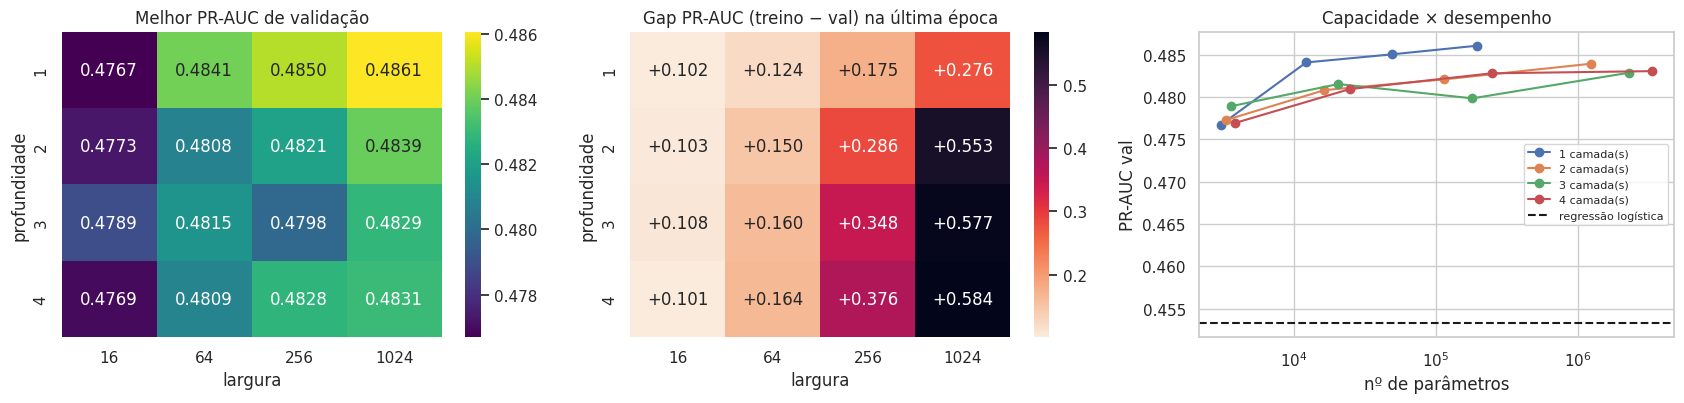

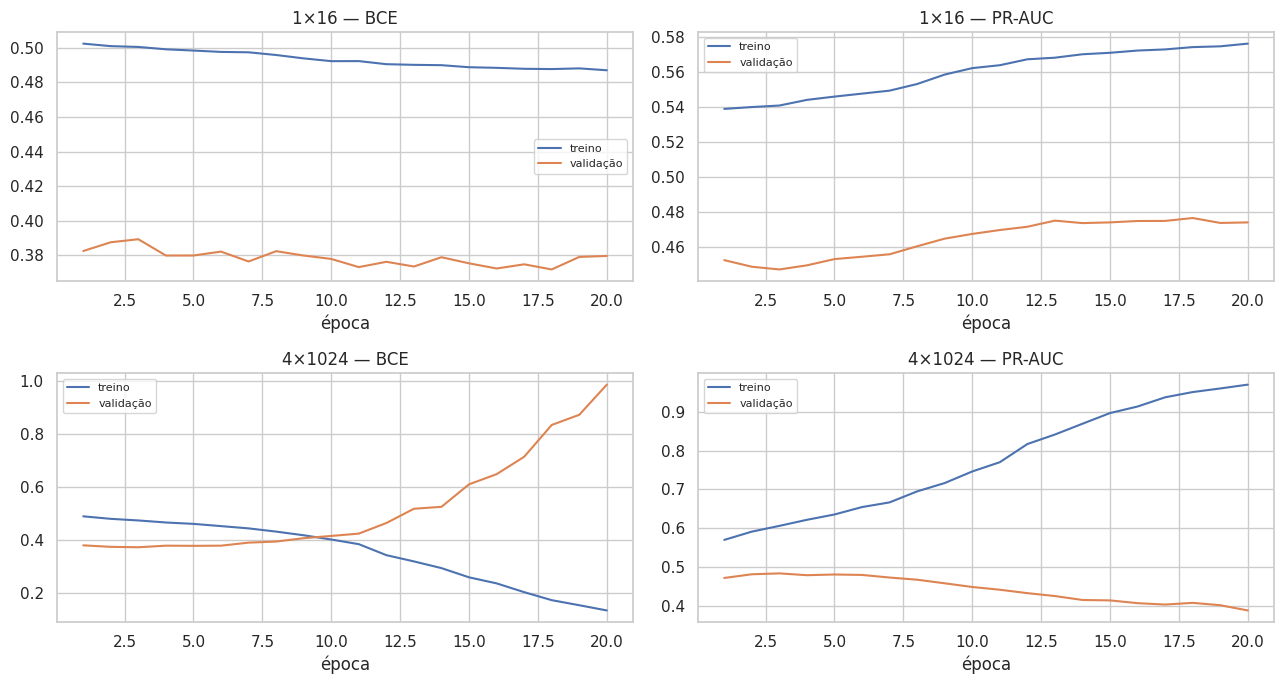

,profundidade,largura,n_params,ap_val_melhor,melhor_epoca,ap_val_final,gap_ap_final,gap_loss_final,tempo_por_epoca_s
0,0,0,189,0.4533,3,0.4473,0.0932,-0.1145,0.4038
1,1,16,3041,0.4767,18,0.4742,0.1021,-0.1074,0.4954
2,1,64,12161,0.4841,13,0.4783,0.1236,-0.0984,0.5060
3,1,256,48641,0.4850,12,0.4731,0.1755,-0.0713,0.5053
4,1,1024,194561,0.4861,5,0.4503,0.2758,-0.0039,0.5208
5,2,16,3313,0.4773,13,0.4712,0.1035,-0.1074,0.5488
6,2,64,16321,0.4808,12,0.4730,0.1497,-0.0870,0.5580
7,2,256,114433,0.4821,5,0.4445,0.2858,0.0030,0.5921
8,2,1024,1244161,0.4839,3,0.3999,0.5529,0.4371,0.9904
9,3,16,3585,0.4789,13,0.4760,0.1075,-0.1063,0.6220


In [15]:
g = res_grid[res_grid['profundidade'] > 0]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.heatmap(g.pivot(index='profundidade', columns='largura', values='ap_val_melhor'), annot=True, fmt='.4f', cmap='viridis', ax=ax[0])
ax[0].set_title('Melhor PR-AUC de validação')
sns.heatmap(g.pivot(index='profundidade', columns='largura', values='gap_ap_final'), annot=True, fmt='+.3f', cmap='rocket_r', ax=ax[1])
ax[1].set_title('Gap PR-AUC (treino − val) na última época')
for prof, gg in g.groupby('profundidade'):
    ax[2].plot(gg['n_params'], gg['ap_val_melhor'], marker='o', label=f'{prof} camada(s)')
lr_ap = res_grid.loc[res_grid['profundidade'] == 0, 'ap_val_melhor'].iloc[0]
ax[2].axhline(lr_ap, color='k', ls='--', label='regressão logística')
ax[2].set_xscale('log'); ax[2].set_xlabel('nº de parâmetros'); ax[2].set_ylabel('PR-AUC val'); ax[2].legend(fontsize=8)
ax[2].set_title('Capacidade × desempenho')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp1_heatmaps.png', dpi=120); plt.show()

# Curvas da menor e da maior rede para visualizar sub/overfitting
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_curvas(hist_grid[(1, 16)], '1×16', ax[0, 0], ax[0, 1])
plot_curvas(hist_grid[(4, 1024)], '4×1024', ax[1, 0], ax[1, 1])
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp1_curvas.png', dpi=120); plt.show()
display(res_grid[['profundidade', 'largura', 'n_params', 'ap_val_melhor', 'melhor_epoca', 'ap_val_final',
                  'gap_ap_final', 'gap_loss_final', 'tempo_por_epoca_s']].round(4))

**Como interpretar:**
- **Subajuste:** redes muito pequenas (e a regressão logística) têm PR-AUC de treino e de validação parecidas e mais baixas. A rede não consegue representar interações não lineares, por exemplo idade × saturação × comorbidades.
- **Overfitting:** redes largas e profundas sem regularização chegam ao melhor resultado de validação cedo e depois a PR-AUC de validação cai (ou a BCE de validação sobe) enquanto o treino continua melhorando. O *gap* da última época cresce com a capacidade.
- **Custo:** o nº de parâmetros cresce com largura² × profundidade e o tempo por época acompanha. Observe a partir de que ponto o ganho de validação deixa de compensar o custo.

## 7. Experimento 2 — Estratégias de regularização
Com centenas de milhares de exemplos, uma MLP desse tamanho dificilmente sofre overfitting forte. Para **tornar o fenômeno observável** e comparar as estratégias de forma clara, usamos um treino pequeno (`REG_TRAIN_N` exemplos) e uma rede de alta capacidade (3 × 512). A validação continua sendo 2022.

| Variante | Configuração |
|---|---|
| Sem regularização | sem dropout, sem penalidade, sem parada antecipada (modelo da última época) |
| Parada antecipada | paciência = 5 épocas, restaura a melhor época |
| Dropout | p = 0,3 |
| L2 | penalidade λ·Σw², λ = 1e-4 |
| L1 | penalidade λ·Σ\|w\|, λ = 1e-5 (induz esparsidade) |
| BatchNorm | normalização em cada camada oculta |
| Combinada | dropout 0,3 + L2 1e-4 + parada antecipada |

In [16]:
Xtr_r, ytr_r = to_t(X_tr[idx_reg_tr]), to_t(y_tr[idx_reg_tr])
base_reg = dict(n_camadas=3, largura=512, lr=1e-3, batch_size=256, ativacao='relu')
VARIANTES = {
    'Sem regularização': (dict(), None, False),
    'Parada antecipada': (dict(), 5, True),
    'Dropout 0.3':       (dict(dropout=0.3), None, False),
    'L2 1e-4':           (dict(l2=1e-4), None, False),
    'L1 1e-5':           (dict(l1=1e-5), None, False),
    'BatchNorm':         (dict(batchnorm=True), None, False),
    'Combinada':         (dict(dropout=0.3, l2=1e-4), 5, True),
}
res_reg, hist_reg = [], {}
for nome, (extra, pac, restaura) in VARIANTES.items():
    _, h, r = treinar(dict(base_reg, **extra), Xtr_r, ytr_r, Xva_h, yva_h, max_epocas=MAX_EPOCAS_REG,
                      paciencia=pac, restaurar_melhor=restaura)
    r['variante'] = nome
    # desempenho do modelo efetivamente entregue (melhor época se restaurado, senão a última)
    r['ap_val_entregue'] = r['ap_val_melhor'] if restaura else r['ap_val_final']
    res_reg.append(r); hist_reg[nome] = h
    print(f"{nome:<18} | épocas={r['epocas']:>3} | AP_val melhor={r['ap_val_melhor']:.4f} (ép {r['melhor_epoca']}) "
          f"| entregue={r['ap_val_entregue']:.4f} | gap final={r['gap_ap_final']:+.4f} | {r['tempo_treino_s']:.0f}s")
res_reg = pd.DataFrame(res_reg).set_index('variante')
res_reg.to_csv(f'{OUT_DIR}/exp2_regularizacao.csv')

Sem regularização  | épocas= 80 | AP_val melhor=0.4556 (ép 2) | entregue=0.3751 | gap final=+0.6246 | 21s
Parada antecipada  | épocas=  7 | AP_val melhor=0.4556 (ép 2) | entregue=0.4556 | gap final=+0.2828 | 2s
Dropout 0.3        | épocas= 80 | AP_val melhor=0.4586 (ép 5) | entregue=0.3848 | gap final=+0.6149 | 23s
L2 1e-4            | épocas= 80 | AP_val melhor=0.4557 (ép 2) | entregue=0.3671 | gap final=+0.6329 | 25s
L1 1e-5            | épocas= 80 | AP_val melhor=0.4536 (ép 3) | entregue=0.3599 | gap final=+0.6401 | 24s
BatchNorm          | épocas= 80 | AP_val melhor=0.4399 (ép 2) | entregue=0.3731 | gap final=+0.6268 | 26s
Combinada          | épocas= 12 | AP_val melhor=0.4586 (ép 7) | entregue=0.4586 | gap final=+0.2472 | 4s


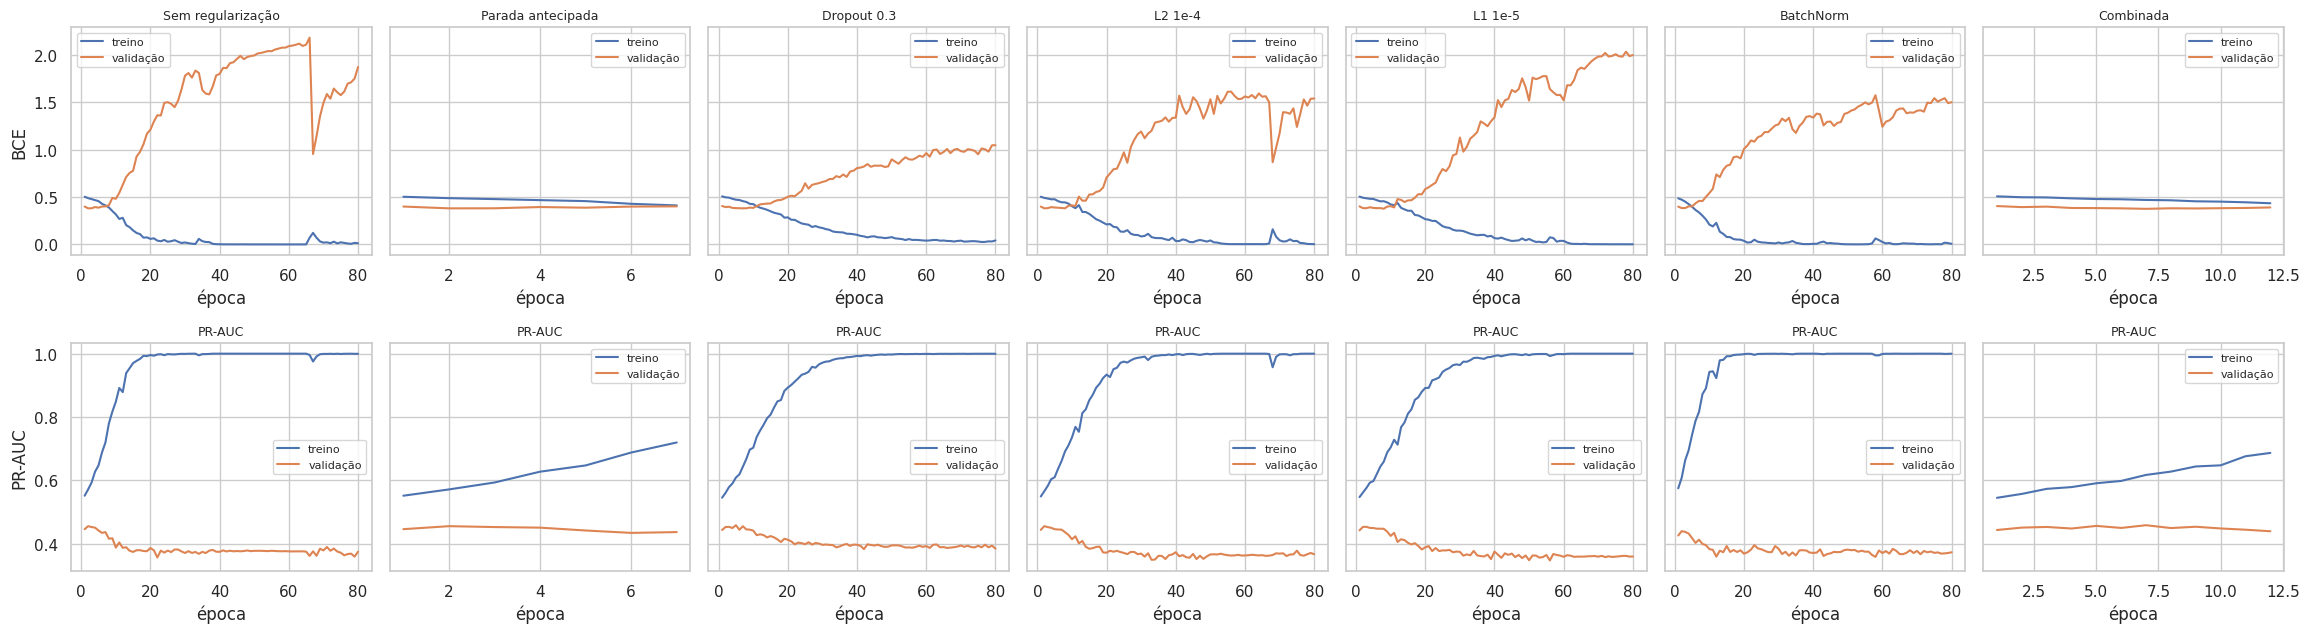

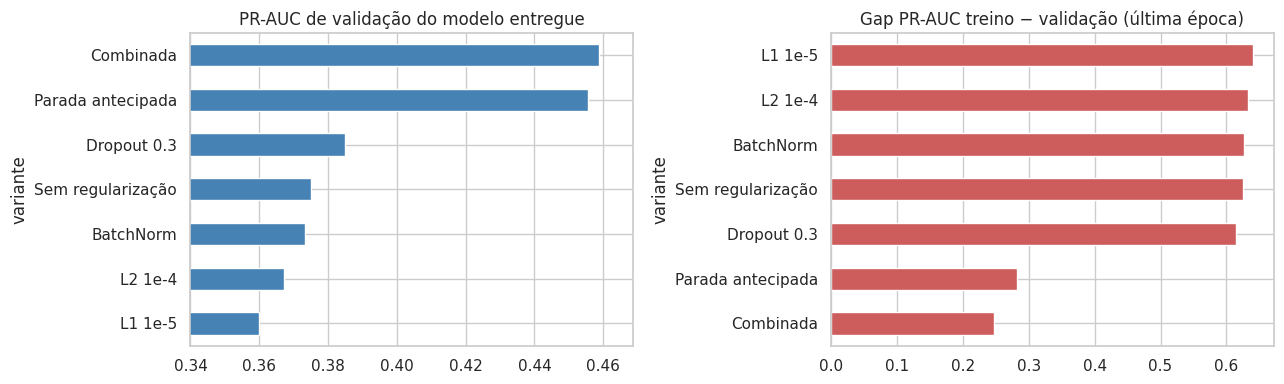

,epocas,melhor_epoca,ap_val_melhor,ap_val_final,ap_val_entregue,gap_ap_final,gap_loss_final,tempo_treino_s
variante,,,,,,,,
Sem regularização,80,2,0.4556,0.3751,0.3751,0.6246,1.8618,20.8702
Parada antecipada,7,2,0.4556,0.4369,0.4556,0.2828,-0.0099,1.7830
Dropout 0.3,80,5,0.4586,0.3848,0.3848,0.6149,1.0063,22.8135
L2 1e-4,80,2,0.4557,0.3671,0.3671,0.6329,1.5395,25.0774
L1 1e-5,80,3,0.4536,0.3599,0.3599,0.6401,1.9990,24.2407
BatchNorm,80,2,0.4399,0.3731,0.3731,0.6268,1.4957,25.9488
Combinada,12,7,0.4586,0.4396,0.4586,0.2472,-0.0444,4.0351


In [17]:
n = len(hist_reg)
fig, ax = plt.subplots(2, n, figsize=(3.3 * n, 6.5), sharey='row')
for j, (nome, h) in enumerate(hist_reg.items()):
    plot_curvas(h, nome, ax[0, j], ax[1, j])
    ax[0, j].set_title(nome, fontsize=9); ax[1, j].set_title('PR-AUC', fontsize=9)
ax[0, 0].set_ylabel('BCE'); ax[1, 0].set_ylabel('PR-AUC')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp2_curvas_regularizacao.png', dpi=120); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res_reg['ap_val_entregue'].sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title('PR-AUC de validação do modelo entregue')
ax[0].set_xlim(res_reg['ap_val_entregue'].min() - 0.02, res_reg['ap_val_entregue'].max() + 0.01)
res_reg['gap_ap_final'].sort_values().plot(kind='barh', ax=ax[1], color='indianred')
ax[1].set_title('Gap PR-AUC treino − validação (última época)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp2_barras.png', dpi=120); plt.show()
display(res_reg[['epocas', 'melhor_epoca', 'ap_val_melhor', 'ap_val_final', 'ap_val_entregue',
                 'gap_ap_final', 'gap_loss_final', 'tempo_treino_s']].round(4))

**Como interpretar:**
- Sem regularização, a BCE de validação passa por um mínimo e **volta a subir**, enquanto a de treino continua caindo: é o overfitting clássico. A PR-AUC entregue (última época) fica abaixo da melhor época.
- A **parada antecipada** não muda o aprendizado, só escolhe a época: entrega o modelo do ponto ótimo com menos tempo de treino.
- **Dropout** e **L2** reduzem o *gap* e tornam a curva de validação mais estável. Valores muito altos levam a subajuste.
- **L1** zera pesos (esparsidade). Com one-hot de muitas categorias raras isso pode ajudar, mas é mais sensível ao valor de λ.
- **BatchNorm** acelera a convergência, mas sozinho regulariza pouco: com amostra pequena ainda pode sofrer overfitting.
- A combinação costuma dar o melhor equilíbrio. Por isso, no Optuna, **dropout**, **weight decay (L2)**, **BatchNorm** e **parada antecipada** fazem parte do espaço de busca ou do protocolo. O L1 ficou fora da busca para economizar tentativas, porque se espera que tenha menos influência que dropout/L2. **Confirme isso na tabela acima** e ajuste o texto se o resultado for outro.

## 8. Experimento 3 — Busca de hiperparâmetros com Optuna

**Configuração do estudo**
- **Amostrador:** TPE (*Tree-structured Parzen Estimator*) multivariado, semente fixa. Ele modela as interações entre hiperparâmetros, por exemplo lr × batch size.
- **Poda:** `MedianPruner`. Interrompe tentativas cuja PR-AUC de validação, numa dada época, está abaixo da mediana das tentativas anteriores na mesma época. Isso economiza tempo nas configurações ruins.
- **Métrica otimizada:** **PR-AUC na validação (2022)**, sem limiar e calculada apenas na validação. O teste não é usado na busca.
- **Dados:** `HPO_TRAIN_N` exemplos do treino e `HPO_VAL_N` da validação. A amostra torna a busca viável no Colab e preserva a ordem relativa entre configurações. As finalistas são depois retreinadas no treino completo.
- **Critério de parada de cada tentativa:** até `MAX_EPOCAS_HPO` épocas com parada antecipada (paciência = `PACIENCIA`).
- **Persistência:** o estudo é salvo em SQLite. Se a sessão cair, basta reexecutar a célula e a busca continua de onde parou.

**Espaço de busca e justificativa dos intervalos**

| Hiperparâmetro | Intervalo | Justificativa |
|---|---|---|
| `lr` | 1e-4 a 1e-2 (log) | hiperparâmetro mais influente. Abaixo de 1e-4 converge devagar demais e acima de 1e-2 o Adam fica instável |
| `n_camadas` | 1 a 5 | o Exp. 1 mostra ganhos decrescentes a partir de 2–3 camadas. 5 já cobre o regime de maior capacidade |
| `largura` | 32 a 1024 (potências de 2) | do subajuste ao overfitting observado no Exp. 1 |
| `formato` | constante, funil | o funil (largura ÷ 2 a cada camada) reduz parâmetros mantendo a profundidade |
| `ativacao` | ReLU, GELU, SiLU | ativações modernas comuns. Diferença esperada pequena, por isso só 3 opções |
| `dropout` | 0 a 0,5 | acima de 0,5 tende a subajuste em dados tabulares |
| `weight_decay` (L2) | 1e-6 a 1e-1 (log) | cobre desde regularização desprezível até forte |
| `batchnorm` | sim / não | afeta estabilidade e velocidade de convergência |
| `batch_size` | 256 a 4096 | troca entre ruído do gradiente (generalização) e tempo por época |
| `balancear` | sim / não | `pos_weight` na BCE para a classe óbito |

In [18]:
def sugerir_cfg(trial):
    return dict(
        lr=trial.suggest_float('lr', 1e-4, 1e-2, log=True),
        n_camadas=trial.suggest_int('n_camadas', 1, 5),
        largura=trial.suggest_categorical('largura', [32, 64, 128, 256, 512, 1024]),
        formato=trial.suggest_categorical('formato', ['constante', 'funil']),
        ativacao=trial.suggest_categorical('ativacao', ['relu', 'gelu', 'silu']),
        dropout=trial.suggest_float('dropout', 0.0, 0.5),
        weight_decay=trial.suggest_float('weight_decay', 1e-6, 1e-1, log=True),
        batchnorm=trial.suggest_categorical('batchnorm', [False, True]),
        batch_size=trial.suggest_categorical('batch_size', [256, 512, 1024, 2048, 4096]),
        balancear=trial.suggest_categorical('balancear', [False, True]),
    )

def objetivo(trial):
    cfg = sugerir_cfg(trial)
    _, h, r = treinar(cfg, Xtr_h, ytr_h, Xva_h, yva_h, max_epocas=MAX_EPOCAS_HPO, paciencia=PACIENCIA, trial=trial)
    for k in ['n_params', 'camadas', 'epocas', 'melhor_epoca', 'gap_ap_melhor', 'gap_ap_final', 'tempo_treino_s', 'tempo_por_epoca_s']:
        trial.set_user_attr(k, r[k])
    return r['ap_val_melhor']

nome_estudo = 'srag_mlp_rapido' if RAPIDO else 'srag_mlp'
estudo = optuna.create_study(
    study_name=nome_estudo, direction='maximize', load_if_exists=True,
    storage=f'sqlite:///{OUT_DIR}/optuna_{nome_estudo}.db',
    sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True, n_startup_trials=min(10, N_TRIALS)),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))

restantes = N_TRIALS - len([t for t in estudo.trials if t.state.is_finished()])
t0 = time.time()
if restantes > 0:
    estudo.optimize(objetivo, n_trials=restantes, show_progress_bar=True, gc_after_trial=True)
print(f'Busca: {time.time()-t0:.0f}s | tentativas: {len(estudo.trials)} | melhor PR-AUC val = {estudo.best_value:.4f}')
print('Melhores hiperparâmetros:', estudo.best_params)

Busca: 0s | tentativas: 40 | melhor PR-AUC val = 0.4893
Melhores hiperparâmetros: {'lr': 0.002183739434679766, 'n_camadas': 5, 'largura': 512, 'formato': 'funil', 'ativacao': 'gelu', 'dropout': 0.2622943187314189, 'weight_decay': 0.015045471367490487, 'batchnorm': False, 'batch_size': 512, 'balancear': True}


In [19]:
df_trials = estudo.trials_dataframe(attrs=('number', 'value', 'state', 'params', 'user_attrs', 'duration'))
df_trials.columns = [c.replace('params_', '').replace('user_attrs_', '') for c in df_trials.columns]
df_trials['duracao_s'] = df_trials['duration'].dt.total_seconds()
df_trials = df_trials.drop(columns=['duration'])
df_trials.to_csv(f'{OUT_DIR}/exp3_optuna_tentativas.csv', index=False)
print(df_trials['state'].value_counts().to_dict())
completos = df_trials[df_trials['state'] == 'COMPLETE'].sort_values('value', ascending=False)
display(Markdown('**Top 10 tentativas (PR-AUC de validação):**'))
display(completos.head(10)[['number', 'value', 'n_camadas', 'largura', 'formato', 'ativacao', 'dropout',
                            'weight_decay', 'batchnorm', 'batch_size', 'lr', 'balancear', 'n_params',
                            'melhor_epoca', 'gap_ap_melhor', 'tempo_treino_s']].round(5))

{'PRUNED': 23, 'COMPLETE': 17}


**Top 10 tentativas (PR-AUC de validação):**

,number,value,n_camadas,largura,formato,ativacao,dropout,weight_decay,batchnorm,batch_size,lr,balancear,n_params,melhor_epoca,gap_ap_melhor,tempo_treino_s
26,26,0.48928,5,512,funil,gelu,0.26229,0.01505,False,512,0.00218,True,271361.0,10.0,0.13023,27.03929
29,29,0.48903,5,512,funil,gelu,0.19809,0.00081,False,512,0.00148,True,271361.0,10.0,0.13696,27.15417
24,24,0.48857,4,512,funil,gelu,0.08894,0.02020,False,512,0.00147,True,269313.0,7.0,0.12446,19.17374
21,21,0.48756,5,512,funil,gelu,0.14925,0.00239,False,512,0.00246,True,271361.0,10.0,0.15210,26.91617
23,23,0.48561,4,512,funil,gelu,0.10456,0.00057,False,512,0.00562,True,269313.0,7.0,0.13094,19.51480
20,20,0.48551,5,512,funil,relu,0.06280,0.00074,False,512,0.00812,True,271361.0,8.0,0.11033,23.23101
22,22,0.48546,5,512,funil,gelu,0.04834,0.00145,False,512,0.00571,True,271361.0,4.0,0.11192,16.48085
28,28,0.48486,5,256,funil,gelu,0.12148,0.00250,False,512,0.00220,True,92161.0,7.0,0.12596,22.57841
25,25,0.48357,4,512,funil,gelu,0.05693,0.02624,False,2048,0.00567,True,269313.0,3.0,0.10499,4.37378
13,13,0.48335,4,512,funil,relu,0.01619,0.00016,False,512,0.00259,True,269313.0,7.0,0.14171,19.64584


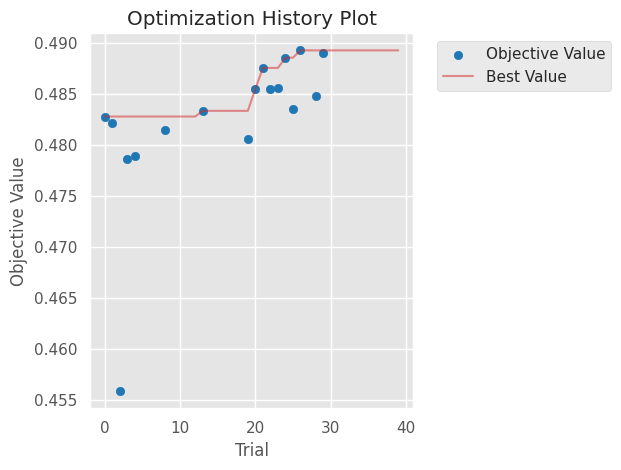

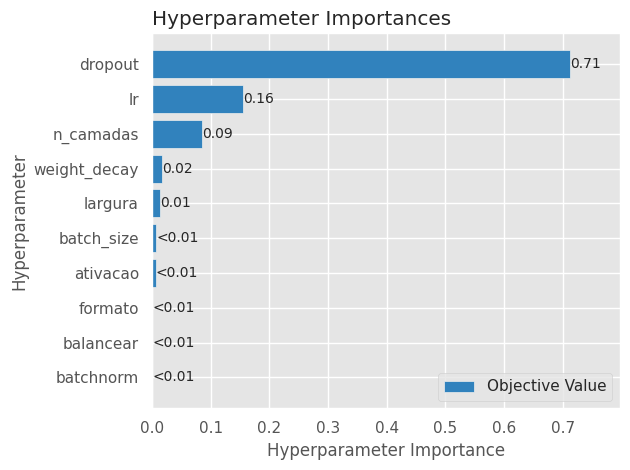

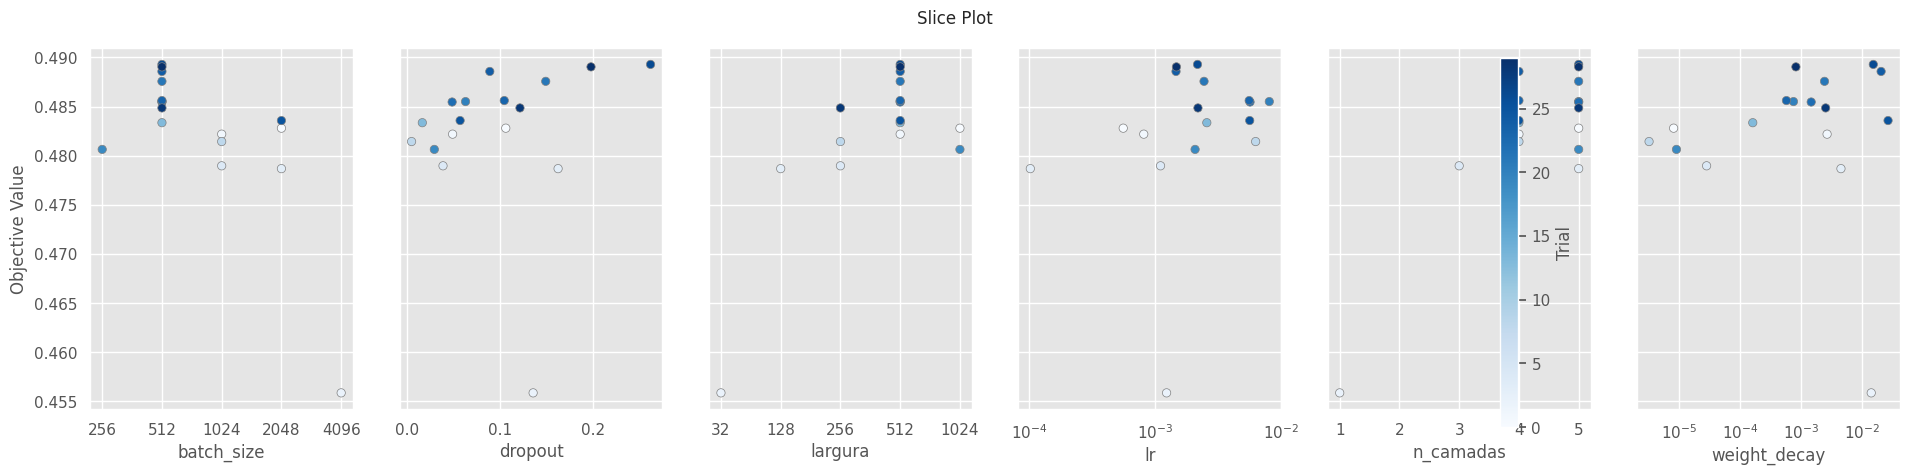

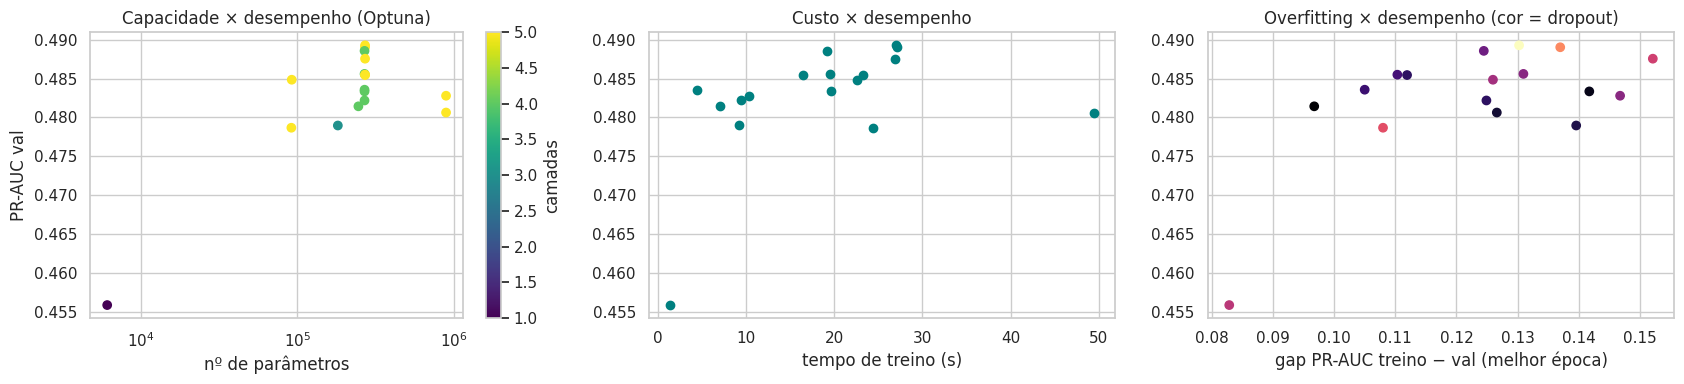

In [20]:
from optuna.visualization import matplotlib as ovm
try:
    ovm.plot_optimization_history(estudo); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/exp3_historico.png', dpi=120); plt.show()
    ovm.plot_param_importances(estudo); plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/exp3_importancias.png', dpi=120); plt.show()
    ovm.plot_slice(estudo, params=['lr', 'n_camadas', 'largura', 'dropout', 'weight_decay', 'batch_size'])
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp3_slice.png', dpi=110); plt.show()
except Exception as e:
    print('Gráfico do Optuna indisponível:', e)
sns.set_theme(style='whitegrid', context='notebook')   # o Optuna troca o estilo global do matplotlib

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sc = ax[0].scatter(completos['n_params'], completos['value'], c=completos['n_camadas'], cmap='viridis')
ax[0].set_xscale('log'); ax[0].set_xlabel('nº de parâmetros'); ax[0].set_ylabel('PR-AUC val'); plt.colorbar(sc, ax=ax[0], label='camadas')
ax[0].set_title('Capacidade × desempenho (Optuna)')
ax[1].scatter(completos['tempo_treino_s'], completos['value'], c='teal')
ax[1].set_xlabel('tempo de treino (s)'); ax[1].set_title('Custo × desempenho')
ax[2].scatter(completos['gap_ap_melhor'], completos['value'], c=completos['dropout'], cmap='magma')
ax[2].set_xlabel('gap PR-AUC treino − val (melhor época)'); ax[2].set_title('Overfitting × desempenho (cor = dropout)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/exp3_dispersao.png', dpi=120); plt.show()

## 9. Seleção e comparação de arquiteturas promissoras
A partir do Optuna selecionamos **três variações** com perfis diferentes de custo e capacidade:
1. **MLP-Optuna-Top1:** melhor tentativa da busca.
2. **MLP-Compacta:** tentativa com **menos parâmetros** entre as que ficaram a até 0,005 de PR-AUC da melhor. Testa se é possível ter o mesmo desempenho com custo menor.
3. **MLP-Alta capacidade:** tentativa com **mais parâmetros** entre as 10 melhores. Testa se capacidade extra traz ganho ou só overfitting.

Como referências entram a **regressão logística** (MLP sem camadas ocultas) e uma **MLP base** escolhida à mão (2 × 128, sem regularização).

Todas as configurações são **retreinadas no treino completo (2020–2021)** com parada antecipada na validação (2022), com `N_SEEDS_FINAL` sementes para estimar a variância. O **limiar de decisão** de cada modelo é escolhido na validação, maximizando a Macro-F1. O teste (2023) só é usado depois, para estimar o desempenho final.

In [21]:
CHAVES_CFG = ['lr', 'n_camadas', 'largura', 'formato', 'ativacao', 'dropout', 'weight_decay', 'batchnorm', 'batch_size', 'balancear']

def cfg_de(linha):
    c = {k: linha[k] for k in CHAVES_CFG}
    c['n_camadas'], c['largura'], c['batch_size'] = int(c['n_camadas']), int(c['largura']), int(c['batch_size'])
    c['batchnorm'], c['balancear'] = bool(c['batchnorm']), bool(c['balancear'])
    return c

top1 = completos.iloc[0]
proximas = completos[completos['value'] >= top1['value'] - 0.005]
compacta = proximas.sort_values('n_params').iloc[0]
if compacta['number'] == top1['number'] and len(completos) > 1:
    compacta = completos[completos['number'] != top1['number']].sort_values('n_params').iloc[0]
usados = {top1['number'], compacta['number']}
grande_cands = completos.head(10)[~completos.head(10)['number'].isin(usados)]
grande = (grande_cands if len(grande_cands) else completos[~completos['number'].isin(usados)]).sort_values('n_params').iloc[-1]

FINALISTAS = {
    'Regressão logística': dict(n_camadas=0, largura=1, lr=1e-3, batch_size=2048, weight_decay=0.0),
    'MLP base (2×128)': dict(n_camadas=2, largura=128, lr=1e-3, batch_size=1024, ativacao='relu'),
    f"MLP-Optuna-Top1 (#{int(top1['number'])})": cfg_de(top1),
    f"MLP-Compacta (#{int(compacta['number'])})": cfg_de(compacta),
    f"MLP-Alta capacidade (#{int(grande['number'])})": cfg_de(grande),
}
for k, v in FINALISTAS.items():
    print(f'{k:<36} {v}')
with open(f'{OUT_DIR}/finalistas_config.json', 'w') as f:
    json.dump(FINALISTAS, f, indent=2, default=str)

Regressão logística                  {'n_camadas': 0, 'largura': 1, 'lr': 0.001, 'batch_size': 2048, 'weight_decay': 0.0}
MLP base (2×128)                     {'n_camadas': 2, 'largura': 128, 'lr': 0.001, 'batch_size': 1024, 'ativacao': 'relu'}
MLP-Optuna-Top1 (#26)                {'lr': np.float64(0.002183739434679766), 'n_camadas': 5, 'largura': 512, 'formato': 'funil', 'ativacao': 'gelu', 'dropout': np.float64(0.2622943187314189), 'weight_decay': np.float64(0.015045471367490487), 'batchnorm': False, 'batch_size': 512, 'balancear': True}
MLP-Compacta (#28)                   {'lr': np.float64(0.0022008164981400765), 'n_camadas': 5, 'largura': 256, 'formato': 'funil', 'ativacao': 'gelu', 'dropout': np.float64(0.12147928061862452), 'weight_decay': np.float64(0.0024973905574217116), 'batchnorm': False, 'batch_size': 512, 'balancear': True}
MLP-Alta capacidade (#20)            {'lr': np.float64(0.008117301084858697), 'n_camadas': 5, 'largura': 512, 'formato': 'funil', 'ativacao': 'relu', 

In [22]:
Xtr_f, ytr_f = to_t(X_tr[idx_fin_tr]), to_t(y_tr[idx_fin_tr])
Xva_t, yva_t = to_t(X_va), to_t(y_va)
Xte_t = to_t(X_te)
print('Treino final:', tuple(Xtr_f.shape), '| validação:', tuple(Xva_t.shape), '| teste:', tuple(Xte_t.shape))

def tempo_inferencia(modelo, X, rep=3):
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(rep):
        prever_proba(modelo, X)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t0) / rep / len(X) * 1e6   # microssegundos por amostra

linhas, HIST_FINAL, PROBAS, MODELOS = [], {}, {}, {}
for nome, cfg in FINALISTAS.items():
    for s in range(N_SEEDS_FINAL):
        seed = SEED + s
        modelo, h, r = treinar(cfg, Xtr_f, ytr_f, Xva_t, yva_t, max_epocas=MAX_EPOCAS_FINAL, paciencia=PACIENCIA, seed=seed)
        p_va, p_te = prever_proba(modelo, Xva_t), prever_proba(modelo, Xte_t)
        lim = melhor_limiar(y_va, p_va)                       # limiar escolhido na VALIDAÇÃO
        mv, mt = metricas(y_va, p_va, lim), metricas(y_te, p_te, lim)
        linha = dict(modelo=nome, seed=seed, n_params=r['n_params'], camadas=r['camadas'], epocas=r['epocas'],
                     melhor_epoca=r['melhor_epoca'], tempo_treino_s=r['tempo_treino_s'],
                     inferencia_us_amostra=tempo_inferencia(modelo, Xte_t), gap_ap_melhor=r['gap_ap_melhor'])
        linha.update({f'val_{k}': v for k, v in mv.items()})
        linha.update({f'teste_{k}': v for k, v in mt.items()})
        linhas.append(linha)
        if s == 0:
            HIST_FINAL[nome], PROBAS[nome], MODELOS[nome] = h, (p_va, p_te, lim), modelo
        print(f"{nome:<36} seed={seed} | ép={r['epocas']:>2} | val PR-AUC={mv['PR_AUC']:.4f} F1m={mv['F1_macro']:.4f} "
              f"| teste PR-AUC={mt['PR_AUC']:.4f} F1m={mt['F1_macro']:.4f} | {r['tempo_treino_s']:.0f}s")
        del modelo; gc.collect()
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()

res_final = pd.DataFrame(linhas)
res_final.to_csv(f'{OUT_DIR}/finalistas_por_seed.csv', index=False)

Treino final: (2512120, 188) | validação: (470059, 188) | teste: (241411, 188)
Regressão logística                  seed=42 | ép= 6 | val PR-AUC=0.4521 F1m=0.6714 | teste PR-AUC=0.3705 F1m=0.6694 | 10s
Regressão logística                  seed=43 | ép= 6 | val PR-AUC=0.4528 F1m=0.6722 | teste PR-AUC=0.3705 F1m=0.6698 | 9s
Regressão logística                  seed=44 | ép= 6 | val PR-AUC=0.4520 F1m=0.6718 | teste PR-AUC=0.3687 F1m=0.6687 | 10s
MLP base (2×128)                     seed=42 | ép=13 | val PR-AUC=0.4971 F1m=0.6863 | teste PR-AUC=0.3919 F1m=0.6807 | 55s
MLP base (2×128)                     seed=43 | ép=16 | val PR-AUC=0.4993 F1m=0.6866 | teste PR-AUC=0.3936 F1m=0.6807 | 68s
MLP base (2×128)                     seed=44 | ép=11 | val PR-AUC=0.5004 F1m=0.6865 | teste PR-AUC=0.3938 F1m=0.6806 | 48s
MLP-Optuna-Top1 (#26)                seed=42 | ép=14 | val PR-AUC=0.5003 F1m=0.6866 | teste PR-AUC=0.3963 F1m=0.6814 | 184s
MLP-Optuna-Top1 (#26)                seed=43 | ép= 8 | val P

In [23]:
cols = ['n_params', 'epocas', 'tempo_treino_s', 'inferencia_us_amostra', 'gap_ap_melhor',
        'val_PR_AUC', 'val_ROC_AUC', 'val_F1_macro', 'teste_PR_AUC', 'teste_ROC_AUC', 'teste_F1_macro',
        'teste_acuracia', 'teste_acuracia_bal', 'teste_precisao_obito', 'teste_recall_obito', 'teste_especificidade', 'teste_brier']
media = res_final.groupby('modelo', sort=False)[cols].mean()
desvio = res_final.groupby('modelo', sort=False)[cols].std().fillna(0)
tabela = media.copy().astype(object)
for c in cols:
    if c in ('n_params',):
        tabela[c] = media[c].map('{:,.0f}'.format)
    elif c in ('epocas', 'tempo_treino_s', 'inferencia_us_amostra'):
        tabela[c] = [f'{m:.1f} ± {d:.1f}' for m, d in zip(media[c], desvio[c])]
    else:
        tabela[c] = [f'{m:.4f} ± {d:.4f}' for m, d in zip(media[c], desvio[c])]
tabela.to_csv(f'{OUT_DIR}/tabela_comparativa_finalistas.csv')
display(Markdown(f'**Comparação das arquiteturas (média ± desvio em {N_SEEDS_FINAL} sementes). Limiar escolhido na validação.**'))
display(tabela)

# Modelo escolhido: maior PR-AUC média na VALIDAÇÃO (o teste não participa da escolha)
ESCOLHIDO = media['val_PR_AUC'].idxmax()
print('Modelo escolhido pela validação:', ESCOLHIDO)

**Comparação das arquiteturas (média ± desvio em 3 sementes). Limiar escolhido na validação.**

,n_params,epocas,tempo_treino_s,inferencia_us_amostra,gap_ap_melhor,val_PR_AUC,val_ROC_AUC,val_F1_macro,teste_PR_AUC,teste_ROC_AUC,teste_F1_macro,teste_acuracia,teste_acuracia_bal,teste_precisao_obito,teste_recall_obito,teste_especificidade,teste_brier
modelo,,,,,,,,,,,,,,,,,
Regressão logística,189,6.0 ± 0.0,9.5 ± 0.0,0.0 ± 0.0,0.0866 ± 0.0041,0.4523 ± 0.0004,0.8103 ± 0.0002,0.6718 ± 0.0004,0.3699 ± 0.0010,0.8580 ± 0.0001,0.6693 ± 0.0006,0.8621 ± 0.0012,0.7083 ± 0.0014,0.3486 ± 0.0021,0.5183 ± 0.0045,0.8982 ± 0.0018,0.0768 ± 0.0004
MLP base (2×128),"40,833",13.3 ± 2.5,57.2 ± 10.5,0.1 ± 0.0,0.1282 ± 0.0022,0.4989 ± 0.0017,0.8244 ± 0.0004,0.6865 ± 0.0002,0.3931 ± 0.0011,0.8675 ± 0.0001,0.6807 ± 0.0001,0.8742 ± 0.0015,0.7081 ± 0.0027,0.3787 ± 0.0030,0.5029 ± 0.0079,0.9133 ± 0.0025,0.0743 ± 0.0017
MLP-Optuna-Top1 (#26),"271,361",12.3 ± 3.8,162.1 ± 48.8,0.2 ± 0.0,0.1118 ± 0.0066,0.5005 ± 0.0021,0.8247 ± 0.0008,0.6866 ± 0.0008,0.4003 ± 0.0045,0.8689 ± 0.0011,0.6823 ± 0.0014,0.8749 ± 0.0012,0.7099 ± 0.0031,0.3812 ± 0.0028,0.5062 ± 0.0078,0.9136 ± 0.0019,0.1040 ± 0.0033
MLP-Compacta (#28),"92,161",10.3 ± 3.5,132.8 ± 44.2,0.1 ± 0.0,0.1192 ± 0.0089,0.4986 ± 0.0017,0.8239 ± 0.0011,0.6857 ± 0.0011,0.3951 ± 0.0012,0.8673 ± 0.0006,0.6804 ± 0.0023,0.8745 ± 0.0009,0.7072 ± 0.0055,0.3789 ± 0.0015,0.5007 ± 0.0132,0.9137 ± 0.0023,0.1042 ± 0.0034
MLP-Alta capacidade (#20),"271,361",13.3 ± 6.7,175.1 ± 86.4,0.2 ± 0.0,0.1038 ± 0.0060,0.4937 ± 0.0028,0.8222 ± 0.0008,0.6837 ± 0.0016,0.3923 ± 0.0046,0.8669 ± 0.0009,0.6790 ± 0.0018,0.8727 ± 0.0021,0.7078 ± 0.0049,0.3745 ± 0.0045,0.5042 ± 0.0129,0.9114 ± 0.0035,0.1040 ± 0.0055


Modelo escolhido pela validação: MLP-Optuna-Top1 (#26)


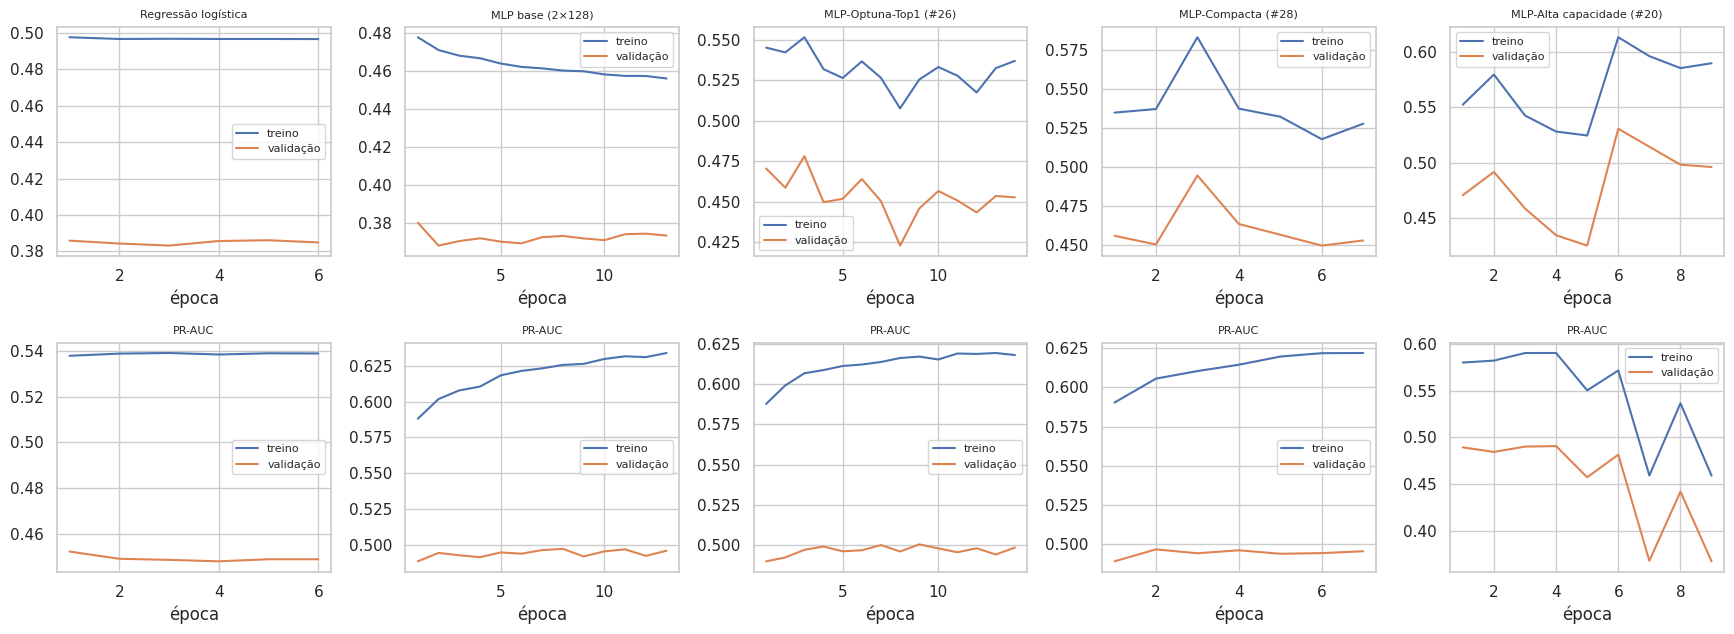

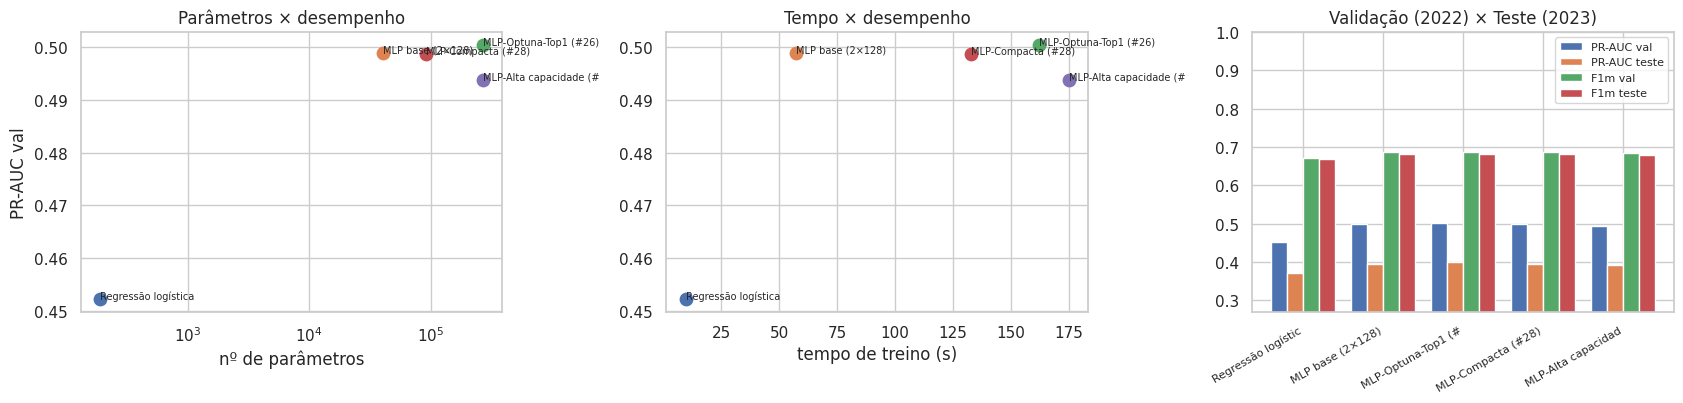

In [24]:
n = len(HIST_FINAL)
fig, ax = plt.subplots(2, n, figsize=(3.5 * n, 6.5))
for j, (nome, h) in enumerate(HIST_FINAL.items()):
    plot_curvas(h, nome, ax[0, j], ax[1, j])
    ax[0, j].set_title(nome, fontsize=8); ax[1, j].set_title('PR-AUC', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/finalistas_curvas.png', dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
m = media.reset_index()
for _, r in m.iterrows():
    ax[0].scatter(r['n_params'], r['val_PR_AUC'], s=80); ax[0].annotate(r['modelo'][:22], (r['n_params'], r['val_PR_AUC']), fontsize=7)
    ax[1].scatter(r['tempo_treino_s'], r['val_PR_AUC'], s=80); ax[1].annotate(r['modelo'][:22], (r['tempo_treino_s'], r['val_PR_AUC']), fontsize=7)
ax[0].set_xscale('log'); ax[0].set_xlabel('nº de parâmetros'); ax[0].set_ylabel('PR-AUC val'); ax[0].set_title('Parâmetros × desempenho')
ax[1].set_xlabel('tempo de treino (s)'); ax[1].set_title('Tempo × desempenho')
x = np.arange(len(m)); w = 0.2
for k, (c, rot) in enumerate([('val_PR_AUC', 'PR-AUC val'), ('teste_PR_AUC', 'PR-AUC teste'),
                              ('val_F1_macro', 'F1m val'), ('teste_F1_macro', 'F1m teste')]):
    ax[2].bar(x + (k - 1.5) * w, m[c], w, label=rot)
ax[2].set_xticks(x); ax[2].set_xticklabels([s[:18] for s in m['modelo']], rotation=30, ha='right', fontsize=8)
ax[2].set_ylim(max(0, m[['val_PR_AUC', 'teste_PR_AUC']].min().min() - 0.1), 1); ax[2].legend(fontsize=8)
ax[2].set_title('Validação (2022) × Teste (2023)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/finalistas_custo_efetividade.png', dpi=120); plt.show()

## 10. Avaliação final no conjunto de teste (2023)
O modelo foi escolhido pela **validação**. Aqui medimos seu desempenho em 2023, dados nunca usados para ajustar pesos, transformações, hiperparâmetros ou limiar.

**MLP-Optuna-Top1 (#26)** — limiar = 0.60 (escolhido na validação)

,validação (2022),teste (2023)
PR_AUC,0.5003,0.3963
ROC_AUC,0.8245,0.8680
F1_macro,0.6866,0.6814
acuracia,0.7952,0.8736
acuracia_bal,0.7065,0.7107
precisao_obito,0.4506,0.3780
recall_obito,0.5670,0.5094
especificidade,0.8460,0.9119
brier,0.1537,0.1008
limiar,0.6000,0.6000


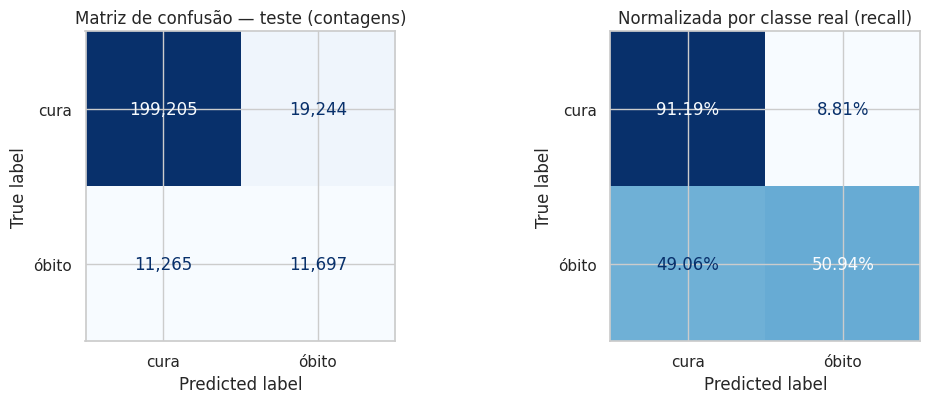

In [25]:
p_va, p_te, lim = PROBAS[ESCOLHIDO]
mv, mt = metricas(y_va, p_va, lim), metricas(y_te, p_te, lim)
display(Markdown(f'**{ESCOLHIDO}** — limiar = {lim:.2f} (escolhido na validação)'))
display(pd.DataFrame({'validação (2022)': mv, 'teste (2023)': mt}).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_te.astype(int), (p_te >= lim).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['cura', 'óbito']).plot(ax=ax[0], cmap='Blues', values_format=',d', colorbar=False)
ax[0].set_title('Matriz de confusão — teste (contagens)')
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=['cura', 'óbito']).plot(ax=ax[1], cmap='Blues', values_format='.2%', colorbar=False)
ax[1].set_title('Normalizada por classe real (recall)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/teste_matriz_confusao.png', dpi=120); plt.show()

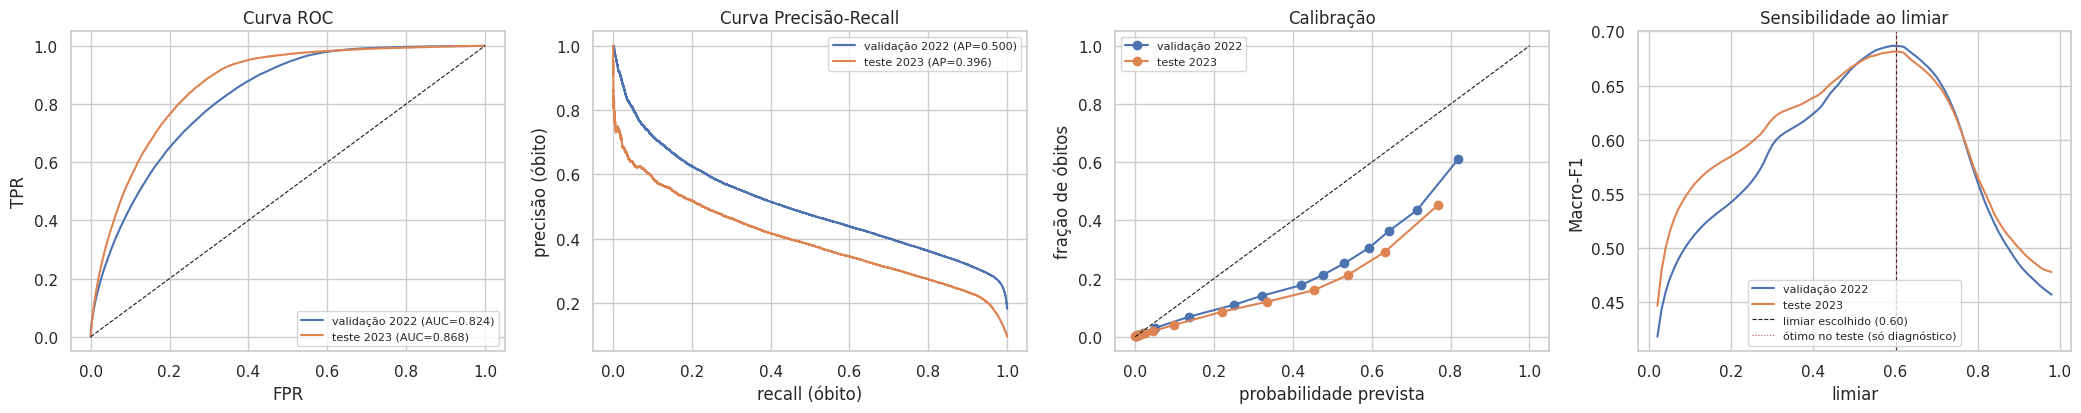

In [26]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
for nome_p, y, p in [('validação 2022', y_va, p_va), ('teste 2023', y_te, p_te)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f'{nome_p} (AUC={roc_auc_score(y, p):.3f})')
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f'{nome_p} (AP={average_precision_score(y, p):.3f})')
    fp_, mp_ = calibration_curve(y, p, n_bins=15, strategy='quantile'); ax[2].plot(mp_, fp_, marker='o', label=nome_p)
    ax[3].plot(LIMIARES, f1_macro_limiares(y, p, LIMIARES), label=nome_p)
ax[0].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title('Curva ROC')
ax[1].set_xlabel('recall (óbito)'); ax[1].set_ylabel('precisão (óbito)'); ax[1].set_title('Curva Precisão-Recall')
ax[2].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[2].set_xlabel('probabilidade prevista'); ax[2].set_ylabel('fração de óbitos'); ax[2].set_title('Calibração')
ax[3].axvline(lim, color='k', ls='--', lw=0.8, label=f'limiar escolhido ({lim:.2f})')
ax[3].axvline(LIMIARES[np.argmax(f1_macro_limiares(y_te, p_te, LIMIARES))], color='r', ls=':', lw=0.8, label='ótimo no teste (só diagnóstico)')
ax[3].set_xlabel('limiar'); ax[3].set_ylabel('Macro-F1'); ax[3].set_title('Sensibilidade ao limiar')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/teste_curvas.png', dpi=120); plt.show()

### 10.1 Onde o modelo falha? Desempenho por faixa etária e ao longo de 2023

**Teste por faixa etária:**

,n,% óbito real,% óbito previsto (média p),ROC_AUC,PR_AUC,recall_obito,especificidade
faixa,,,,,,,
"[0, 18)",138091.0,1.229,3.026,0.776,0.061,0.027,0.998
"[18, 40)",12679.0,8.715,14.492,0.790,0.267,0.138,0.980
"[40, 60)",19870.0,16.387,32.798,0.735,0.352,0.304,0.915
"[60, 70)",18527.0,20.484,45.714,0.714,0.398,0.458,0.823
"[70, 80)",22793.0,23.073,52.947,0.704,0.422,0.581,0.716
"[80, 120)",29441.0,26.647,60.046,0.699,0.469,0.728,0.548


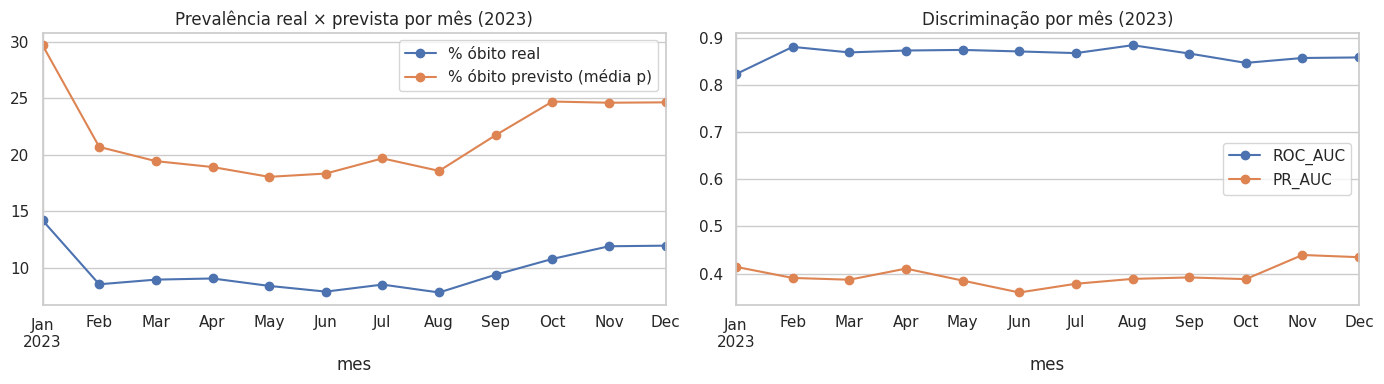

In [27]:
pred_te = (p_te >= lim).astype(int)
aux = pd.DataFrame({'y': y_te.astype(int), 'p': p_te, 'pred': pred_te,
                    'faixa': pd.cut(meta_te['IDADE'], [0, 18, 40, 60, 70, 80, 120], right=False),
                    'mes': meta_te['MES_SIN_PRI']})
def resumo_grupo(g):
    ok = g['y'].nunique() == 2
    return pd.Series({'n': len(g), '% óbito real': 100 * g['y'].mean(), '% óbito previsto (média p)': 100 * g['p'].mean(),
                      'ROC_AUC': roc_auc_score(g['y'], g['p']) if ok else np.nan,
                      'PR_AUC': average_precision_score(g['y'], g['p']) if ok else np.nan,
                      'recall_obito': g.loc[g['y'] == 1, 'pred'].mean() if g['y'].sum() else np.nan,
                      'especificidade': 1 - g.loc[g['y'] == 0, 'pred'].mean() if (g['y'] == 0).sum() else np.nan})
por_faixa = aux.groupby('faixa', observed=True).apply(resumo_grupo)
display(Markdown('**Teste por faixa etária:**')); display(por_faixa.round(3))
por_mes = aux.dropna(subset=['mes']).groupby('mes').apply(resumo_grupo)
por_mes = por_mes[por_mes['n'] >= 100]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_mes[['% óbito real', '% óbito previsto (média p)']].plot(ax=ax[0], marker='o'); ax[0].set_title('Prevalência real × prevista por mês (2023)')
por_mes[['ROC_AUC', 'PR_AUC']].plot(ax=ax[1], marker='o'); ax[1].set_title('Discriminação por mês (2023)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/teste_por_mes.png', dpi=120); plt.show()
por_faixa.to_csv(f'{OUT_DIR}/teste_por_faixa_etaria.csv'); por_mes.to_csv(f'{OUT_DIR}/teste_por_mes.csv')

### 10.2 Quais variáveis o modelo mais usa? (importância por permutação no teste)
Permutamos conjuntamente todas as colunas geradas por uma variável original (ex.: todas as dummies de `SATURACAO`) e medimos a queda da PR-AUC. Quanto maior a queda, mais o modelo depende dessa variável. Isso indica associação aprendida, não causalidade.

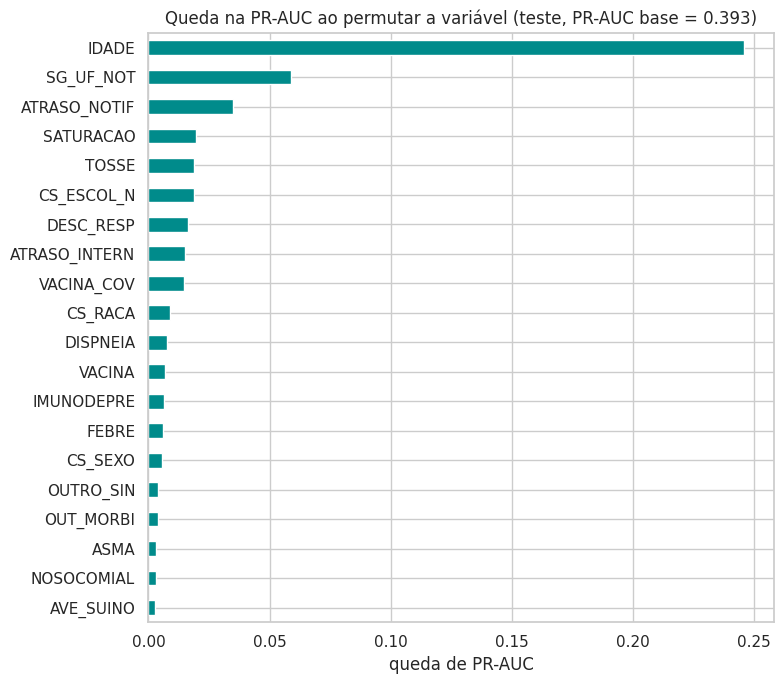

In [28]:
modelo_esc = MODELOS[ESCOLHIDO]
n_imp = min(len(X_te), 50_000 if not RAPIDO else 5_000)
idx_imp = np.random.default_rng(SEED).choice(len(X_te), n_imp, replace=False)
X_imp, y_imp = to_t(X_te[idx_imp]), y_te[idx_imp]
ap_base = average_precision_score(y_imp, prever_proba(modelo_esc, X_imp))
imp = {}
for var, cols_v in GRUPOS.items():
    quedas = []
    for r in range(3):
        perm = torch.from_numpy(np.random.default_rng(SEED + r).permutation(n_imp)).to(DEVICE)
        Xp = X_imp.clone(); cols_t = torch.tensor(cols_v, device=DEVICE)
        Xp[:, cols_t] = X_imp[perm][:, cols_t]
        quedas.append(ap_base - average_precision_score(y_imp, prever_proba(modelo_esc, Xp)))
    imp[var] = np.mean(quedas)
imp = pd.Series(imp).sort_values()
imp.to_csv(f'{OUT_DIR}/importancia_permutacao.csv')
imp.tail(20).plot(kind='barh', figsize=(8, 7), color='darkcyan')
plt.title(f'Queda na PR-AUC ao permutar a variável (teste, PR-AUC base = {ap_base:.3f})'); plt.xlabel('queda de PR-AUC')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/importancia_permutacao.png', dpi=120); plt.show()

### 10.3 Resumo numérico para o relatório e exportação dos resultados

In [29]:
resumo = {
    'particoes': {p: {'anos': a, 'n': int((df['PARTICAO'] == p).sum()), 'taxa_obito': float(df.loc[df['PARTICAO'] == p, 'y'].mean())}
                  for p, a in PARTICOES.items()},
    'n_features_entrada': int(X_tr.shape[1]),
    'optuna': {'n_tentativas': len(estudo.trials), 'completas': int((df_trials['state'] == 'COMPLETE').sum()),
               'podadas': int((df_trials['state'] == 'PRUNED').sum()), 'melhor_pr_auc_val': float(estudo.best_value),
               'melhores_params': estudo.best_params},
    'modelo_escolhido': ESCOLHIDO, 'config_escolhida': FINALISTAS[ESCOLHIDO], 'limiar': lim,
    'metricas_validacao': mv, 'metricas_teste': mt,
}
with open(f'{OUT_DIR}/resumo_resultados.json', 'w') as f:
    json.dump(resumo, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(json.dumps(resumo, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))

import shutil
arq = shutil.make_archive('/content/resultados_srag_mlp' if os.path.isdir('/content') else os.path.join(OUT_DIR, '..', 'resultados_srag_mlp'),
                          'zip', OUT_DIR)
print('Resultados compactados em', arq)
try:
    from google.colab import files
    files.download(arq)
except Exception:
    pass

{
  "particoes": {
    "treino": {
      "anos": [
        2020,
        2021
      ],
      "n": 2512120,
      "taxa_obito": 0.28194194544846585
    },
    "validacao": {
      "anos": [
        2022
      ],
      "n": 470059,
      "taxa_obito": 0.18218989531101415
    },
    "teste": {
      "anos": [
        2023
      ],
      "n": 241411,
      "taxa_obito": 0.09511579836875701
    }
  },
  "n_features_entrada": 188,
  "optuna": {
    "n_tentativas": 40,
    "completas": 17,
    "podadas": 23,
    "melhor_pr_auc_val": 0.4892834147315473,
    "melhores_params": {
      "lr": 0.002183739434679766,
      "n_camadas": 5,
      "largura": 512,
      "formato": "funil",
      "ativacao": "gelu",
      "dropout": 0.2622943187314189,
      "weight_decay": 0.015045471367490487,
      "batchnorm": false,
      "batch_size": 512,
      "balancear": true
    }
  },
  "modelo_escolhido": "MLP-Optuna-Top1 (#26)",
  "config_escolhida": {
    "lr": 0.002183739434679766,
    "n_camadas": 5,
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Limitações e conclusões (roteiro para a discussão)

**Limitações e fontes de incerteza**
- **Mudança temporal (*dataset shift*).** Entre 2020–2021 e 2023 mudaram a variante dominante, a cobertura vacinal, os protocolos clínicos e a prevalência de óbito. Compare a PR-AUC/ROC-AUC de validação e de teste e a calibração: a queda indica quanto o modelo depende do contexto de treino. Uma probabilidade prevista acima da taxa real em 2023 indica que o modelo herdou a letalidade mais alta do treino.
- **Mudanças de esquema da ficha.** `VACINA_COV` não existe em 2020 e outros campos mudaram de preenchimento ao longo dos anos. O modelo pode associar "campo vazio" a um período, e não ao risco clínico.
- **Qualidade do preenchimento.** Muitos campos ficam vazios ou como "ignorado". Erros de digitação foram tratados apenas nos casos evidentes (idades e atrasos impossíveis).
- **Viés de seleção.** Só entram casos notificados, hospitalizados e com desfecho encerrado. Casos sem desfecho (ainda em aberto ou perdidos) podem ter perfil diferente.
- **Sem identificador de paciente.** Notificações repetidas da mesma pessoa não podem ser agrupadas. O risco de uma mesma pessoa aparecer em partições diferentes é baixo, porque elas são anos distintos, mas não pode ser descartado.
- **Escopo da previsão.** Excluímos variáveis da evolução hospitalar (UTI, ventilação) para evitar vazamento. Com elas o desempenho subiria, mas a pergunta passaria a ser outra: prever o desfecho já conhecendo o agravamento.
- **Associação ≠ causalidade.** A importância por permutação mostra o que o modelo usa, não o efeito causal de cada fator.

**Conclusões (preencher com os números obtidos)**
1. Efeito de largura/profundidade (Exp. 1): a partir de qual capacidade o ganho satura e onde aparece overfitting.
2. Regularização (Exp. 2): qual estratégia mais reduziu o *gap* e qual entregou a melhor PR-AUC.
3. Optuna (Exp. 3): hiperparâmetros mais importantes (gráfico fANOVA) e configuração final.
4. Comparação das finalistas: ganho da MLP sobre a regressão logística e custo (parâmetros, tempo) de cada variação.
5. Generalização temporal: diferença entre validação (2022) e teste (2023), efeito no limiar e na calibração, e faixas etárias em que o modelo erra mais.